# 08 — Tannen features from gold annotation, rolled up to speakers, mapped in 3-D

**What this notebook does, in order.** (1) Restricts the corpus to the conversations whose dialog
acts were labelled by humans on both sides — 986 of the 1,994 sliced conversations — so every speaker
in the analysis has full gold coverage. (2) Counts every Tannen-relevant behaviour the human annotation
records: dialog acts, disfluency markup, laughter — counts, no model, no threshold. (3) Trains an
open-source topic model (LDA) on all 2,438 transcripts and derives topic-cohesion columns. (4) Joins
those with the Thomas et al. (2018) variables, each replaced by the in-house extractor where that one
measures the construct better. (5) Asks, feature by feature, whether a speaker behaves like themselves
from call to call (ICC), and rolls up to speakers only where that is true. (6) Compresses the speaker
table through a 3-unit autoencoder bottleneck — no PCA anywhere — (7) tests whether speakers form
clusters, (8) reads what the three axes mean, (9) tests whether gender, education, age and region
separate in the map, and (10) draws it.

**Decisions ledger** (2026-09-29, Dain's directive; the R1 skeleton this replaces is archived verbatim
at `analysis/archive/08_measurement_R1_skeleton.ipynb`, its plan at
`docs/archive/NB08_MEASUREMENT_PLAN_R1_2026-09-29.md`):
- **Base set** = conversations with gold dialog acts on both sides.
- **Gold features are counted from the SwDA release directly** — one annotation source for all 986
  (NXT's 642 are a subset of SwDA), each SwDA side mapped to its ms98 audio channel by the word
  alignment `gold_acts` already validated (83 conversations are A/B-swapped).
- **Thomas et al.'s eleven enter through the better route** (S4 gives the reason per variable).
  Loudness and pitch spread enter as coefficients of variation, because the linear / Hz spreads track
  the level itself (S5 measures r .98 / .66).
- **Prior exclusions stand, not re-litigated:** rising terminals (2026-09-06), Empath (2026-09-07),
  the repetition trio (Deprecated 2026-09-12).
- **Roll-up rule:** a feature is rolled up to speakers only if its side-level ICC has a
  caller-bootstrap 95% CI above 0; caller values are empirical-Bayes (Kelley) estimates.
- **Embedding:** a 3-unit autoencoder (scikit-learn MLP) is the only dimensionality reduction; t-SNE
  (random initialisation) is a second view. No PCA anywhere.
- **Clusters** are claimed only if a Gaussian mixture prefers k ≥ 2 by BIC in the 3-D code **and** in
  the full feature space, beyond what a structureless null with the same correlations produces — and
  S7 measures how far apart two groups must be before this pipeline can see them at all.

**Honesty framing.** These rules were fixed before this notebook's run but after prototyping on the
same data (2026-09-29): decision rules stated before the final run, not a pre-registration. Every
number below is computed here; nothing is carried in from earlier notebooks.

In [1]:
# Provenance, imports, and the constants every section uses.
import subprocess, sys, datetime, time, warnings, json, html
from pathlib import Path
import numpy as np, pandas as pd
import scipy, sklearn
from scipy.stats import spearmanr, norm, rankdata, ttest_ind
from scipy.spatial.distance import pdist
from diptest import diptest
from sklearn.decomposition import LatentDirichletAllocation  # noqa: F401  (used via topic_cohesion)
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict, cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.cluster import KMeans
from sklearn.metrics import homogeneity_completeness_v_measure, adjusted_mutual_info_score, v_measure_score, mutual_info_score
import matplotlib.pyplot as plt
from swb_extract import nxt, swda, gold_side as GS, topic_cohesion as TC
from swb_extract.analysis import load_features_table
from swb_extract.speaker_map import bh_fdr, encode, fit_ae, gmm_best_k, copula_sampler, write_map_html, icc1, kelley_table
from swb_extract.features.inhouse.machine_gun_question import MAX_TOKENS as MGQ_MAX_TOKENS, MAX_ONSET_SEC as MGQ_MAX_ONSET

REPO = Path("..").resolve()
TR = REPO / "swb_ms98_transcriptions_cleaned"
DERIVED = REPO / "utterances_v2" / "derived"
T_START = time.time()
_git = lambda *a: subprocess.run(["git", "-C", str(REPO), *a], capture_output=True, text=True).stdout.strip()
print(f"NB08 · {datetime.date.today()} · HEAD {_git('rev-parse', '--short', 'HEAD')}"
      f"{' + uncommitted changes' if _git('status', '--porcelain') else ''} · python {sys.version.split()[0]}"
      f" · numpy {np.__version__} · pandas {pd.__version__} · scikit-learn {sklearn.__version__} · scipy {scipy.__version__}")

ICC_BOOT = 1000          # caller-bootstrap replicates for ICC CIs
AE_SEEDS = 20            # autoencoder restarts
N_NULL = 30              # structureless-null replicates for the cluster test
POWER_REPS = 20          # replicates per planted separation
N_PERM = 1000            # label permutations per demographic test
CV_SEEDS = 5             # CV fold shuffles averaged for each observed statistic

def elapsed():
    return f"[{time.time() - T_START:,.0f} s]"

NB08 · 2026-09-29 · HEAD 0efd102 + uncommitted changes · python 3.14.0 · numpy 2.4.4 · pandas 3.0.5 · scikit-learn 1.8.0 · scipy 1.17.1


In [2]:
# NB08-specific helpers; the shared ones (bh_fdr, icc1, kelley_table, fit_ae, encode, gmm_best_k, copula_sampler,
# write_map_html) live in swb_extract.speaker_map and are unit-tested in tests/test_speaker_map.py.
def icc_with_ci(vals, groups, B=ICC_BOOT, seed=0):
    """ICC(1) plus a percentile 95% CI from resampling whole callers."""
    vals, groups = np.asarray(vals, float), np.asarray(groups)
    est = icc1(vals, groups)
    callers = np.unique(groups); idx = {c: np.flatnonzero(groups == c) for c in callers}
    rng = np.random.default_rng(seed); boots = np.empty(B)
    for b in range(B):
        pick = rng.choice(callers, len(callers), replace=True)
        ii = np.concatenate([idx[c] for c in pick])
        gg = np.repeat(np.arange(len(pick)), [len(idx[c]) for c in pick])
        boots[b] = icc1(vals[ii], gg)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return est, lo, hi

def gold_base(tag):
    """First base act of a Gold Act tag; NXT's '%-' spelling folded onto SwDA's '%'."""
    if not isinstance(tag, str) or not tag:
        return None
    b = (nxt.parse_tag(tag)[0] or ("",))[0]
    return "%" if b.startswith("%") else b

# Known-answer check of the ICC estimator: 300 callers × 2–8 sides, true ICC .40.
_rng = np.random.default_rng(42); _g = np.repeat(np.arange(300), _rng.integers(2, 9, 300))
_v = np.sqrt(0.4) * _rng.standard_normal(300)[_g] + np.sqrt(0.6) * _rng.standard_normal(len(_g))
_icc = icc_with_ci(_v, _g, B=300)
print(f"ICC known-answer check: true .400, estimated {_icc[0]:.3f} (95% CI {_icc[1]:.3f}–{_icc[2]:.3f})")
assert _icc[1] < 0.4 < _icc[2]
assert np.allclose(bh_fdr([0.01, 0.02, 0.03, 0.5]), [0.04, 0.04, 0.04, 0.5])

ICC known-answer check: true .400, estimated 0.408 (95% CI 0.349–0.460)


## S1 — The base set: full gold dialog-act coverage

**What:** keep a conversation only if **both** of its sides carry human-labelled dialog acts (the
`Gold Act` column: NXT's time join for 544 conversations, SwDA's text join for the rest). A
conversation with one labelled side is dropped whole — a speaker's listener behaviour is measured
against the partner's talk, so both sides must be labelled. **Speaker** = the caller (`caller_no`), not
the conversation side: a caller appears in several conversations.

**Check:** the counts are asserted, so a changed input table fails here instead of shifting every
number downstream.

In [3]:
df_all = load_features_table(include="provisional")
_k = df_all["Utterance File Name"].str.extract(r"sw(\d{4})([AB])-U(\d+)")
df_all["conv"], df_all["side"] = _k[0].astype(int), _k[1]

cc = pd.read_csv(REPO / "tables/call_con_tab.csv", header=None, skipinitialspace=True,
                 names=["conv", "side", "caller", "phone", "length", "topic", "remarks", "active"])
cc["side"] = cc["side"].str.strip().str.strip('"')

_lab = df_all[df_all["Gold Act"].notna()].groupby(["conv", "side"]).size()
_per_conv = _lab.reset_index().groupby("conv").size()
BASE = sorted(_per_conv[_per_conv == 2].index)
u = df_all[df_all["conv"].isin(BASE)].merge(cc[["conv", "side", "caller"]], on=["conv", "side"],
                                              how="left", validate="many_to_one")
assert u["caller"].notna().all()
u["gold_b0"] = u["Gold Act"].map(gold_base)
u["gold_sub"] = u["gold_b0"].notna() & ~u["gold_b0"].isin(GS.NONSUBSTANTIVE)

sides = u.groupby(["conv", "side"]).size()
print(f"sliced corpus: {df_all['conv'].nunique():,} conversations; gold on ≥1 side: {len(_per_conv):,}; "
      f"on both sides: {len(BASE):,} (dropped {int((_per_conv == 1).sum())} with one side labelled)")
print(f"base set: {len(BASE):,} conversations · {len(sides):,} sides · {u['caller'].nunique()} callers · "
      f"{len(u):,} ms98 utterances ({u['Gold Act'].notna().mean():.1%} carry a gold act; "
      f"{u['gold_sub'].mean():.1%} are gold-substantive, i.e. not listener acts, non-verbal or abandoned)")
_cpc = u.groupby("caller")["conv"].nunique()
print(f"conversations per caller: median {int(_cpc.median())}, IQR {int(_cpc.quantile(.25))}–{int(_cpc.quantile(.75))}, "
      f"max {_cpc.max()}; callers with ≥2: {(_cpc >= 2).sum()}, ≥3: {(_cpc >= 3).sum()}")
assert (len(BASE), len(sides), u["caller"].nunique()) == (986, 1972, 391)

⚠ loaded 73 feature cols including 27 PROVISIONAL (unconfirmed) — trust with care:
    Question Flag, Echo Question Flag, Machine Gun Question Score, Machine Gun Question Flag, Mutual Revelation Flag, Topic Label  …


sliced corpus: 1,994 conversations; gold on ≥1 side: 1,001; on both sides: 986 (dropped 15 with one side labelled)
base set: 986 conversations · 1,972 sides · 391 callers · 106,509 ms98 utterances (91.9% carry a gold act; 61.4% are gold-substantive, i.e. not listener acts, non-verbal or abandoned)
conversations per caller: median 3, IQR 1–8, max 23; callers with ≥2: 260, ≥3: 220


## S2 — Everything the human annotation lets us count

**What:** for each base conversation, read the SwDA file (one row per slash-unit: a sentence-like unit
of talk with one SWBD-DAMSL act tag and the Treebank transcription), merge `+` continuation rows into
the unit they continue, and count per side (`swb_extract.gold_side`, unit-tested in
`tests/test_gold_side.py`). The table below is the full inventory: every count the gold layer yields,
its corpus total, and whether it becomes a Tannen feature (S4) or stays in the inventory.

**Why SwDA for all 986:** the per-utterance `Gold Act` join keeps only each ms98 utterance's *last*
act, so an utterance holding "yes" plus an elaboration loses the "yes"; counting slash-units directly
keeps every act, and it uses one annotation source for the whole base set.

In [4]:
t0 = time.time()
gold = pd.DataFrame([c for conv in BASE for c in GS.conversation_counts(conv, TR).values()])
gold = gold.merge(cc[["conv", "side", "caller"]], on=["conv", "side"], how="left", validate="one_to_one")
assert len(gold) == 2 * len(BASE) and gold["caller"].notna().all()
print(f"gold side table: {len(gold):,} sides in {time.time() - t0:.1f} s; A/B-swapped conversations: "
      f"{int(gold.groupby('conv')['swapped'].first().sum())}; side alignment ratio median "
      f"{gold['match_ratio'].median():.3f} (min {gold['match_ratio'].min():.3f})")

INVENTORY = [  # count column, what it counts, Tannen anchor (docs/tannen_feature_map.md), use in S4
    ("n_units", "slash-units (logical, + merged)", "—", "denominator"),
    ("n_sub", "substantive units (not listener / x / %)", "—", "denominator"),
    ("n_words", "words", "—", "denominator"),
    ("n_turns", "turns", "Table 3.1 turn counts (PDF p. 85)", "inventory"),
    ("n_q", "questions (qy qw qo qh qr qrr, ^g)", "Ch.7 3d; 'use of frequent questions' p. 204", "q_rate"),
    ("n_info_q", "information questions", "Ch.7 4b", "inventory (inside n_q)"),
    ("n_echo", "echo / backchannel questions (bh, q^m)", "Ch.7 4a; p. 109", "echo_q_rate"),
    ("n_b", "continuers (b)", "Ch.2 2e participatory listenership", "bc_rate"),
    ("n_ba", "appreciations (ba: 'wow', 'that's great')", "Ch.7 3 overt enthusiasm; pp. 156–157", "appreciation_rate"),
    ("n_bk", "response acknowledgements (bk)", "—", "inventory"),
    ("n_bh", "backchannel questions (bh)", "Ch.7 4a", "inside n_echo"),
    ("n_bf", "summarize / reformulate the other (bf)", "Ch.7 6b (ours, weak)", "inventory"),
    ("n_br", "signal non-understanding (br)", "—", "inventory"),
    ("n_compl", "collaborative completions (^2)", "Ch.7 6a finish another's statement; p. 117", "completion_rate"),
    ("n_mirror", "repeats of the other's words (^m)", "Ch.7 6 repetition; p. 131", "mirror_rate"),
    ("n_ans_turns", "answers to yes/no questions", "Ch.7 3c", "denominator"),
    ("n_ans_elab", "answers expanded with ^e", "Ch.7 3c free offer of related material; p. 127", "elaboration_share"),
    ("n_quote", "quotations (^q)", "Ch.2 3c internal evaluation; pp. 172, 183", "quote_rate"),
    ("n_sv", "opinion statements (sv)", "'free offer of opinions' p. 204", "opinion_share"),
    ("n_sd", "non-opinion statements (sd)", "—", "denominator"),
    ("n_hedge", "hedges (h: 'I don't know')", "Chad's hedge, p. 109", "hedge_rate"),
    ("n_hold", "holds before answering (^h)", "Ch.7 3a (ours)", "inventory"),
    ("n_aa", "agreements (aa)", "—", "inventory"),
    ("n_ar", "rejections (ar)", "—", "inventory"),
    ("n_x", "non-verbal units (x)", "—", "inventory"),
    ("n_abandoned", "abandoned units (%)", "—", "inventory"),
    ("n_self_rep", "self-repeats (^r)", "—", "inventory"),
    ("n_about_task", "talk about the task (^t)", "—", "inventory"),
    ("n_F", "filled pauses {F}", "hesitance cues, pp. 109, 112, 154, 164, 173", "filled_pause_rate"),
    ("n_restart", "restarts / repairs [ + ]", "false starts, pp. 109, 154, 164", "restart_rate"),
    ("n_D", "discourse markers {D}", "not listed; 'Well,' + pause read as hesitance, p. 154", "inventory"),
    ("n_E", "editing terms {E}", "—", "inventory"),
    ("n_C", "coordinating conjunctions {C}", "—", "inventory"),
    ("n_A", "asides {A}", "—", "inventory"),
    ("n_laugh", "laughter marks <laughter>", "Ch.7 9 laughter", "gold_laughter_rate"),
    ("n_overlap_marks", "transcriber overlap marks #", "Ch.7 5a", "inventory: partial coverage (S2 check)"),
]
inv = pd.DataFrame([(c, what, anchor, use, int(gold[c].sum()), gold[c].mean(), (gold[c] > 0).mean())
                    for c, what, anchor, use in INVENTORY],
                   columns=["count", "what", "Tannen anchor", "use", "base total", "per side", "sides ≥1"])
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    print(inv.to_string(index=False, formatters={"per side": "{:.2f}".format, "sides ≥1": "{:.0%}".format}))

gold side table: 1,972 sides in 11.4 s; A/B-swapped conversations: 83; side alignment ratio median 0.959 (min 0.801)
          count                                      what                                         Tannen anchor                                    use  base total per side sides ≥1
        n_units           slash-units (logical, + merged)                                                     —                            denominator      183151    92.88     100%
          n_sub  substantive units (not listener / x / %)                                                     —                            denominator      123394    62.57     100%
        n_words                                     words                                                     —                            denominator     1311602   665.11     100%
        n_turns                                     turns                     Table 3.1 turn counts (PDF p. 85)                              inventory      103

### S2 check — does the gold layer agree with an independent transcription?

The ms98 transcripts are a separate human transcription of the same audio (ISIP, not LDC/Treebank). If
the side mapping or the counting were wrong, the two would disagree. Four comparisons per side:
**words** (the mapping test — and for the swapped conversations, against the *other* channel, which
must fail), **questions** (SwDA slash-units vs the per-utterance `Gold Question Flag` join, which keeps
one act per utterance, so it undercounts), **filled pauses** (`{F}` vs ms98 "um"/"uh" tokens), and
**laughter** (two transcribers' laughter marks — their agreement bounds any laughter measure).

In [5]:
_um = u["Transcript"].fillna("").str.split().map(lambda ws: sum(w in ("um", "uh") for w in ws))
ms = (u.assign(_um=_um).groupby(["conv", "side"])
        .agg(ms_words=("token_count", "sum"), ms_q=("Gold Question Flag", "sum"),
             ms_laugh=("Laughter Count", "sum"), ms_um=("_um", "sum")).reset_index())
chk = gold.merge(ms, on=["conv", "side"], validate="one_to_one")
other = ms[["conv", "side", "ms_words"]].assign(side=lambda d: d["side"].map({"A": "B", "B": "A"}))
chk = chk.merge(other.rename(columns={"ms_words": "ms_words_other"}), on=["conv", "side"])
sw = chk[chk["swapped"] == 1]
r = lambda a, b, d=chk: np.corrcoef(d[a], d[b])[0, 1]
CHECK_S2 = {
    "words r (all sides)": r("n_words", "ms_words"),
    "words r (swapped sides, mapped channel)": r("n_words", "ms_words", sw),
    "words r (swapped sides, OTHER channel)": r("n_words", "ms_words_other", sw),
    "questions r": r("n_q", "ms_q"),
    "filled pauses r ({F} vs um/uh)": r("n_F", "ms_um"),
    "laughter r (two transcriptions)": r("n_laugh", "ms_laugh"),
}
for k, v in CHECK_S2.items():
    print(f"  {k:42s} {v:+.3f}")
print(f"  totals: words {chk.n_words.sum():,} vs {chk.ms_words.sum():,.0f}; questions {chk.n_q.sum():,} vs "
      f"{chk.ms_q.sum():,.0f} (one act per ms98 utterance undercounts); filled pauses {chk.n_F.sum():,} vs "
      f"{chk.ms_um.sum():,}; laughter {chk.n_laugh.sum():,} vs {chk.ms_laugh.sum():,.0f}")
_om = gold.groupby("conv")["n_overlap_marks"].sum() > 0
print(f"  transcriber overlap marks (#) present in {_om.sum()} of {len(_om)} conversations ({_om.mean():.0%}) — "
      "a transcriber convention, not an exhaustive annotation, so # is inventory only; overlap comes from the "
      "aligned word times (in-house, S4)")
# Third path: raw tag strings counted straight from the SwDA CSVs — no tag parser, no unit merging —
# must equal the module's per-side counts (``+`` rows never carry these marks, so merging cannot matter).
_raw = []
for conv in BASE:
    for r_ in GS.read_rows(conv):
        t_ = r_["act_tag"].strip()
        _raw.append((conv, r_["caller"].strip().upper(), "^2" in t_, t_.startswith("bh"), "^q" in t_ or t_.startswith('"')))
_raw = pd.DataFrame(_raw, columns=["conv", "swda_side", "compl", "bh", "quote"]).groupby(["conv", "swda_side"]).sum().reset_index()
_cmp = gold.merge(_raw, on=["conv", "swda_side"], validate="one_to_one")
_eq = {k: int((_cmp[a] == _cmp[b]).sum()) for k, a, b in (("completions", "n_compl", "compl"), ("bh questions", "n_bh", "bh"), ("quotations", "n_quote", "quote"))}
print(f"  raw-string recount equals the module on {_eq} of {len(_cmp)} sides")
assert all(v == len(_cmp) for v in _eq.values())
assert CHECK_S2["words r (all sides)"] > 0.99 and CHECK_S2["words r (swapped sides, OTHER channel)"] < 0.3
assert CHECK_S2["questions r"] > 0.85 and CHECK_S2["filled pauses r ({F} vs um/uh)"] > 0.85

  words r (all sides)                        +0.998
  words r (swapped sides, mapped channel)    +0.998
  words r (swapped sides, OTHER channel)     -0.092
  questions r                                +0.921
  filled pauses r ({F} vs um/uh)             +0.895
  laughter r (two transcriptions)            +0.804
  totals: words 1,311,602 vs 1,317,728; questions 8,382 vs 5,928 (one act per ms98 utterance undercounts); filled pauses 40,871 vs 36,479; laughter 10,076 vs 6,343
  transcriber overlap marks (#) present in 527 of 986 conversations (53%) — a transcriber convention, not an exhaustive annotation, so # is inventory only; overlap comes from the aligned word times (in-house, S4)


  raw-string recount equals the module on {'completions': 1972, 'bh questions': 1972, 'quotations': 1972} of 1972 sides


## S3 — A topic model for topic cohesion

**The tool.** Latent Dirichlet allocation (Blei, Ng & Jordan 2003), scikit-learn's implementation —
open source, already installed, and the topic model computational linguists recognise first
(BERTopic is the modern alternative; it would add sentence-transformers, torch, UMAP and HDBSCAN as
dependencies). LDA learns K "topics" — word distributions — from the transcripts alone, then describes
any stretch of talk as a mixture θ of those topics.

**Training:** all 2,438 ms98 conversations, cut into consecutive 150-word windows of both speakers'
talk (stopwords, fillers and contractions removed). The assigned Switchboard topic ("CARE OF THE
ELDERLY", …) is never shown to the model — which makes recovering it a fair test of whether the model
captured what conversations are about.

**The cohesion columns** (per gold turn with ≥5 in-vocabulary words; BC = Bhattacharyya overlap of two
mixtures, 1 = identical): **cohesion** = BC(turn, partner's previous turn) − mean BC(turn, all the
partner's turns in that conversation) — how much more a turn picks up what the partner *just* said
than what the partner talks about in general; **persistence** = BC(turn, own previous turn) −
BC(turn, partner's previous turn) — continuing one's own line rather than the partner's. Book
directions: the high-considerateness speakers respond to others' remarks and "do not toss out new,
unrelated ideas of their own", while the high-involvement three pursue their own topics — "diffuse
talk" (PDF pp. 140–142, 123); "Persist" is on the Ch.2 involvement list (p. 61).

**Checks:** (a) topic recovery — does the conversation's mean mixture predict its assigned topic
(5-fold cross-validated logistic regression, against the majority-class rate)? (b) the shuffle null —
permuting the order of the partner's turns destroys adjacency and must drive cohesion to 0; (c) the
cohesion statistic computed by two independent code paths must agree; (d) K = 25 and 100 beside the
primary K = 50; (e) whose property uptake is — side means grouped by speaker (across a caller's calls)
versus by conversation (the two sides of one call).

In [6]:
t0 = time.time()
docs, doc_conv = TC.training_documents(TR)
conv_tab = pd.read_csv(REPO / "tables/conv_tab.csv", header=None, skipinitialspace=True)
conv_tab[4] = pd.to_numeric(conv_tab[4], errors="coerce")
topic_of = dict(zip(conv_tab[0].astype(int), conv_tab[4]))
topic_names = pd.read_csv(REPO / "tables/topic_tab.csv", header=None, skipinitialspace=True).set_index(1)[0].to_dict()
sw_side = gold.set_index(["conv", "swda_side"])["side"].to_dict()
print(f"training windows: {len(docs):,} from {len(set(doc_conv)):,} conversations  {elapsed()}")

def prompt_recovery(theta):
    dc = np.asarray(doc_conv); convs = np.unique(dc)
    M = np.vstack([theta[dc == c].mean(0) for c in convs])
    y = np.array([topic_of.get(int(c), np.nan) for c in convs])
    ok = ~np.isnan(y); vc = pd.Series(y[ok]).value_counts(); ok &= np.isin(y, vc[vc >= 5].index)
    acc = cross_val_score(LogisticRegression(max_iter=3000, C=10), np.log(M[ok] + 1e-4), y[ok],
                          cv=StratifiedKFold(5, shuffle=True, random_state=0))
    return acc.mean(), acc.std(), vc[vc >= 5].max() / ok.sum(), ok.sum(), (vc >= 5).sum()

def turn_topic_metrics(vec, lda):
    """Per eligible gold turn: conv, ms98 side, cohesion, persistence; plus per-conversation BC matrices."""
    vocab = set(vec.get_feature_names_out())
    turns, meta = [], []
    for conv in BASE:
        for caller, _t, text, sub in GS.turns(GS.read_rows(conv)):
            toks = [w for w in TC.content_tokens(swda.normalize_swda_text(text)) if w in vocab]
            if sub and len(toks) >= TC.MIN_TOKENS:
                turns.append(toks); meta.append((conv, caller))
    th = lda.transform(vec.transform(turns))
    meta = pd.DataFrame(meta, columns=["conv", "caller"])
    rows, bundles = [], []
    for conv, idx in meta.groupby("conv").indices.items():
        callers = meta["caller"].to_numpy()[idx]; th_c = th[idx]
        if len(idx) < 4:
            continue
        sq = np.sqrt(th_c); Bm = sq @ sq.T; bundles.append((callers, Bm))
        for i, mrow in enumerate(TC.conversation_turn_metrics(list(callers), th_c)):
            par = np.flatnonzero(callers != callers[i]); k = np.searchsorted(par, i) - 1
            local = Bm[i, par[k]] if k >= 0 else np.nan          # raw overlap with the partner's last turn
            rows.append((conv, sw_side[(conv, mrow["caller"])], mrow["cohesion"], mrow["persistence"], local))
    return pd.DataFrame(rows, columns=["conv", "side", "cohesion", "persistence", "local"]), bundles

def cohesion_mean(bundles, rng=None):
    """Second, independent path to mean cohesion from BC matrices; rng permutes partner-turn order."""
    vals = []
    for callers, B in bundles:
        for c in ("A", "B"):
            own, par = np.flatnonzero(callers == c), np.flatnonzero(callers != c)
            if len(par) == 0:
                continue
            target = par if rng is None else rng.permutation(par)
            for i in own:
                k = np.searchsorted(par, i) - 1
                if k >= 0:
                    vals.append(B[i, target[k]] - B[i, par].mean())
    return float(np.mean(vals))

TOPIC = {}
for K in (50, 25, 100):
    vec, lda, theta = TC.fit(docs, K, seed=0)
    acc, sd, maj, n_c, n_t = prompt_recovery(theta)
    tt, bundles = turn_topic_metrics(vec, lda)
    TOPIC[K] = dict(vec=vec, lda=lda, turns=tt, bundles=bundles, acc=acc, maj=maj)
    print(f"K={K:3d}: topic recovery {acc:.3f} ± {sd:.3f} over {n_c:,} conversations / {n_t} topics "
          f"(majority class {maj:.3f}); eligible base turns {len(tt):,}; mean cohesion "
          f"{tt['cohesion'].mean():+.4f}, persistence {tt['persistence'].mean():+.4f}  {elapsed()}")

training windows: 20,487 from 2,438 conversations  [16 s]


K= 50: topic recovery 0.689 ± 0.020 over 2,427 conversations / 65 topics (majority class 0.032); eligible base turns 21,374; mean cohesion +0.0288, persistence +0.0164  [86 s]


K= 25: topic recovery 0.691 ± 0.004 over 2,427 conversations / 65 topics (majority class 0.032); eligible base turns 21,374; mean cohesion +0.0289, persistence +0.0160  [146 s]


K=100: topic recovery 0.761 ± 0.018 over 2,427 conversations / 65 topics (majority class 0.032); eligible base turns 21,374; mean cohesion +0.0233, persistence +0.0185  [220 s]


In [7]:
# The K = 50 model: its topics, the shuffle null, and agreement across K.
vec50, lda50 = TOPIC[50]["vec"], TOPIC[50]["lda"]
_vocab = np.array(vec50.get_feature_names_out())
for k in range(lda50.n_components):
    print(f"  topic {k:2d}: " + " ".join(_vocab[np.argsort(-lda50.components_[k])[:9]]))

obs = cohesion_mean(TOPIC[50]["bundles"])
assert abs(obs - TOPIC[50]["turns"]["cohesion"].mean()) < 1e-9     # two code paths, one number
_rng = np.random.default_rng(0)
null = np.array([cohesion_mean(TOPIC[50]["bundles"], _rng) for _ in range(200)])
print(f"\ncohesion, observed {obs:+.4f} vs shuffled partner-turn order {null.mean():+.5f} ± {null.std():.5f} "
      f"(200 shuffles): z = {(obs - null.mean()) / null.std():.1f}; max shuffle {null.max():+.4f}")
_side = {K: TOPIC[K]["turns"].groupby(["conv", "side"])[["cohesion", "persistence"]].mean() for K in TOPIC}
for col in ("cohesion", "persistence"):
    print(f"side-level {col}: r(K25, K50) {_side[25][col].corr(_side[50][col]):.3f} · "
          f"r(K50, K100) {_side[50][col].corr(_side[100][col]):.3f}")
# Whose property is topical uptake — the speaker's, or the conversation's? Side-level means, grouped two ways:
# by caller (a caller's different calls) and by conversation (the two sides of one call).
_ts = TOPIC[50]["turns"].groupby(["conv", "side"])[["local", "cohesion"]].mean().reset_index().merge(
    gold[["conv", "side", "caller"]], on=["conv", "side"])
UPTAKE_ICC = {}
for col in ("local", "cohesion"):
    d = _ts.dropna(subset=[col]); dm = d[d["caller"].map(d["caller"].value_counts()) >= 2]
    UPTAKE_ICC[col] = (icc1(dm[col].to_numpy(), dm["caller"].to_numpy()), icc1(d[col].to_numpy(), d["conv"].to_numpy()))
print("topical uptake, side means — ICC by speaker vs by conversation: raw overlap with the partner's last turn "
      f"{UPTAKE_ICC['local'][0]:+.3f} vs {UPTAKE_ICC['local'][1]:+.3f}; cohesion (net of the conversation's topic) "
      f"{UPTAKE_ICC['cohesion'][0]:+.3f} vs {UPTAKE_ICC['cohesion'][1]:+.3f}")
CHECK_S3 = dict(topic_recovery=TOPIC[50]["acc"], majority=TOPIC[50]["maj"], cohesion_obs=obs,
                shuffle_z=(obs - null.mean()) / null.std())
assert null.max() < obs

  topic  0: car cars drive oil miles thousand driving new bought
  topic  1: women men woman changes change changed way man role
  topic  2: camping water went fish lake fishing nice fun we'd
  topic  3: military group country government involved peace community feel type
  topic  4: care day children child kids want baby taking important
  topic  5: number phone calls privacy social waiting office information list
  topic  6: worth travel europe england fort ahead great would've took
  topic  7: play playing game played football team games baseball ball
  topic  8: gun control guns law shot shoot hunting carry want
  topic  9: wear weather nice cold winter rain dress bye year
  topic 10: texas dallas north lived live area california plano south
  topic 11: service state public want real term honest available does
  topic 12: love fun nice enjoy wonderful real husband great neat
  topic 13: different places type space place types mexican look heavy
  topic 14: seen saw movie movies did


cohesion, observed +0.0288 vs shuffled partner-turn order +0.00004 ± 0.00139 (200 shuffles): z = 20.7; max shuffle +0.0041
side-level cohesion: r(K25, K50) 0.478 · r(K50, K100) 0.540
side-level persistence: r(K25, K50) 0.480 · r(K50, K100) 0.469
topical uptake, side means — ICC by speaker vs by conversation: raw overlap with the partner's last turn +0.043 vs +0.422; cohesion (net of the conversation's topic) -0.002 vs -0.020


## S4 — The map: Thomas + in-house + gold + topic

One row per candidate speaker feature. **Source** says where the number comes from; **replaces** names
the Thomas et al. (2018) variable it stands in for, with the reason in the note; **sign** is the book's
direction where the book gives one (HI+ = more of it on the high-involvement side), taken from
`docs/tannen_feature_map.md`, never from the data. Signs are used only in S8 to *read* the axes — the
autoencoder never sees them. Units: listener behaviours per partner substantive unit (the listening
opportunities), own-talk behaviours per own substantive unit, lexical events per 100 own words.

In [8]:
MAP = pd.DataFrame([
    # feature, construct, source, replaces, Tannen anchor, sign, pages, note
    ("syllable_rate", "rate of speech", "in-house", "wps", "Ch.7 5c · Ch.2 2a", "HI+", "61, 119, 202",
     "syllables handle word length; audited 2026-08-19"),
    ("fto_mean", "floor-transfer offset", "in-house", "poplen", "Ch.7 3a, 5b · Ch.2 2b, 2c", "HI-", "61, 202",
     "backchannel-aware floor transfers; poplen is blank in overlap"),
    ("latch_share", "latched transfers (0–200 ms)", "in-house", "—", "Ch.4 latching", "HI+", "104, 119", ""),
    ("within_pause_rate", "within-turn pausing", "in-house", "wpp, boplen", "Ch.7 2c · Ch.2 4d vs hesitance",
     "unsigned", "61–62, 202", "Thomas' no-F0 pauses measure voicing dropout on 8 kHz audio (AUDIT §4E-h)"),
    ("coop_overlap_rate", "cooperative overlap (substantive)", "in-house × gold", "olap", "Ch.7 5a · Ch.2 2d",
     "HI+", "61, 98, 119, 202", "olap is mostly backchannel lines; gold filter keeps content overlaps"),
    ("obstr_share", "obstructive share of own overlaps", "in-house × gold", "olap", "Ch.7 5a (the contrast)",
     "unsigned", "202", "HC speakers wait; obstruction is not the HC pole"),
    ("loudness_cv", "amplitude variation (gain-free)", "in-house (CV)", "lv", "Ch.7 2a · Ch.2 4b", "HI+",
     "62, 202", "linear spread tracks line gain (S5)"),
    ("pitch_cv", "pitch variation (level-free)", "in-house (CV)", "pv", "Ch.7 2b · Ch.2 4b", "HI+",
     "62, 130, 202", "Hz spread tracks pitch level, i.e. sex (S5)"),
    ("ppron_per_word", "1st/2nd-person pronouns per word", "Thomas route", "ppron", "Ch.7 1 · Ch.2 1a", "HI+",
     "61, 95, 202", "in-house 16-form list, over gold-substantive talk"),
    ("repu", "own-line lexical repetition", "Thomas", "repu", "Ch.2 1d via Thomas T1", "HI+", "61, 131",
     "the paper's 'persistence' bridge"),
    ("words_per_unit", "words per substantive slash-unit", "gold", "wpu", "none (Table 3.1)", "unsigned", "85",
     "human sentence units instead of transcriber lines"),
    ("word_share", "share of the dyad's words", "gold", "—", "'talked the most / least'", "unsigned",
     "84–85, 204–205", ""),
    ("q_rate", "questions", "gold", "—", "Ch.7 3d, 4 · co-occurrence list", "HI+", "203, 204", ""),
    ("echo_q_rate", "echo / backchannel questions", "gold", "—", "Ch.7 4a", "HI+", "109, 203", ""),
    ("bc_rate", "continuers", "gold", "—", "Ch.2 2e participatory listenership", "HI+", "62", ""),
    ("appreciation_rate", "appreciations / exclamations", "gold", "—", "Ch.7 3 · expressive response", "HI+",
     "156–157, 203", ""),
    ("completion_rate", "collaborative completions", "gold", "—", "Ch.7 6a", "HI+", "117, 203", ""),
    ("mirror_rate", "repeats of the other's words", "gold", "—", "Ch.7 6", "HI+", "131, 203", ""),
    ("elaboration_share", "expanded yes/no answers", "gold", "—", "Ch.7 3c free offer", "HI+", "127, 203, 205", ""),
    ("quote_rate", "quotation (constructed dialogue)", "gold", "—", "Ch.2 3c internal evaluation", "HI+",
     "62, 172, 183", ""),
    ("opinion_share", "opinions among statements", "gold", "—", "'free offer of opinions'", "HI+", "204",
     "one sentence about Peter — weak anchor"),
    ("hedge_rate", "hedges", "gold", "—", "Chad's reply, a hedge", "HI-", "109", "one HC speaker's example"),
    ("filled_pause_rate", "filled pauses", "gold", "—", "hesitance cues (HC examples)", "HI-",
     "109, 112, 154, 164, 173", "supersedes the in-house filled-pause rate"),
    ("restart_rate", "restarts / false starts", "gold", "—", "false starts (HC examples)", "HI-",
     "109, 154, 164", ""),
    ("gold_laughter_rate", "laughter (SwDA transcriber)", "gold", "—", "Ch.7 9", "unsigned", "193, 203, 205",
     "HI Steve laughs more, HI Peter never after one-liners"),
    ("laughter_rate", "laughter (ms98 transcriber)", "in-house", "—", "Ch.7 9", "unsigned", "193, 203, 205",
     "second transcription of the same construct"),
    ("mgq_share", "machine-gun questions", "gold × timing", "—", "Ch.7 device 1", "HI+", "112, 142, 203",
     f"gold question, ≤{MGQ_MAX_TOKENS} tokens, onset ≤{MGQ_MAX_ONSET} s; pitch term dropped"),
    ("topic_cohesion", "topical uptake of partner's last turn", "topic model", "—", "Ch.7 7", "HI-",
     "123, 140, 203", ""),
    ("topic_persistence", "own line vs partner's", "topic model", "rept", "Ch.2 1d persist; diffuse talk",
     "HI+", "61, 131, 140–142", ""),
], columns=["feature", "construct", "source", "replaces", "Tannen anchor", "sign", "PDF pages", "note"]).set_index("feature")
with pd.option_context("display.max_colwidth", 48, "display.width", 250):
    print(MAP.drop(columns=["note"]).to_string())
print(f"\n{len(MAP)} candidates: " + ", ".join(f"{k} {v}" for k, v in MAP["source"].value_counts().items()))

                                                construct           source     replaces                       Tannen anchor      sign                PDF pages
feature                                                                                                                                                       
syllable_rate                              rate of speech         in-house          wps                   Ch.7 5c · Ch.2 2a       HI+             61, 119, 202
fto_mean                            floor-transfer offset         in-house       poplen           Ch.7 3a, 5b · Ch.2 2b, 2c       HI-                  61, 202
latch_share                  latched transfers (0–200 ms)         in-house            —                       Ch.4 latching       HI+                 104, 119
within_pause_rate                     within-turn pausing         in-house  wpp, boplen      Ch.7 2c · Ch.2 4d vs hesitance  unsigned               61–62, 202
coop_overlap_rate       cooperative overlap (s

## S5 — Rolling up to speakers, only where speakers are consistent

**What:** every candidate is first computed per conversation side as a ratio of two sums (numerator,
denominator), so a speaker's value later pools the same way. Then the question the roll-up depends on:
**does a caller behave like themselves from call to call?** ICC(1) answers it — the share of side-to-side
variance that sits *between* callers. Think of each call as a noisy reading of the caller: ICC .6 means
most of the spread is people; ICC 0 means a caller's calls look no more alike than calls by strangers,
and averaging them yields noise.

**Rule (stated in the ledger):** a feature rolls up only if its ICC's caller-bootstrap 95% CI lies above
0. Laughter is transcribed twice by independent transcribers; the version with the higher ICC enters and
the other is its check. Any pair of entering features with |ρ| ≥ .8 at caller level would lose its
lower-ICC member (none does — printed). Each caller's value is the **Kelley estimate** μ + ρᵢ(x̄ᵢ − μ),
ρᵢ = kᵢ·ICC / (1 + (kᵢ − 1)·ICC): a caller seen in one call is pulled toward the population mean in
proportion to how little one call says about them. Callers with no defined side for a share (e.g. no
yes/no answers) take the mean (ρ = 0).

**Level check** (why loudness and pitch spread enter as coefficients of variation): printed first.

In [9]:
key = ["conv", "side"]
sub = u[u["gold_sub"]]
_lv = sub.groupby(key).agg(lm=("loudness mean", "mean"), ls=("loudness std", "mean"),
                           pm=("pitch mean", "mean"), ps=("pitch std", "mean"))
print(f"level check (side means over gold-substantive utterances): r(loudness std, loudness mean) "
      f"{_lv.ls.corr(_lv.lm):.3f} · r(pitch std, pitch mean) {_lv.ps.corr(_lv.pm):.3f}")

S = pd.DataFrame(index=pd.MultiIndex.from_frame(gold[key]))
def add(name, num, den):
    S[name + "__num"] = num.reindex(S.index).fillna(0.0)
    S[name + "__den"] = den.reindex(S.index).fillna(0.0)
gk_all, gk_sub = [u["conv"], u["side"]], [sub["conv"], sub["side"]]
_f = u["FTO Sec"].where(u["FTO Sec"].between(-2, 2))
add("fto_mean", _f.groupby(gk_all).sum(), _f.notna().groupby(gk_all).sum())
add("latch_share", u["Latching Flag"].groupby(gk_all).sum(), u["Latching Flag"].notna().groupby(gk_all).sum())
for name, col in (("syllable_rate", "syllable_rate"), ("within_pause_rate", "Within Pause Rate")):
    add(name, sub[col].groupby(gk_sub).sum(), sub[col].notna().groupby(gk_sub).sum())
_lcv = sub["loudness std"] / sub["loudness mean"].where(sub["loudness mean"] > 0)
_pcv = sub["pitch std"] / sub["pitch mean"]
add("loudness_cv", _lcv.groupby(gk_sub).sum(), _lcv.notna().groupby(gk_sub).sum())
add("pitch_cv", _pcv.groupby(gk_sub).sum(), _pcv.notna().groupby(gk_sub).sum())
_lv2 = pd.DataFrame({"lcv": _lcv, "pcv": _pcv, "lm": sub["loudness mean"], "pm": sub["pitch mean"]}).groupby(gk_sub).mean()
print(f"after the CV transform: r(loudness CV, loudness mean) {_lv2.lcv.corr(_lv2.lm):.3f} · "
      f"r(pitch CV, pitch mean) {_lv2.pcv.corr(_lv2.pm):.3f}")
add("ppron_per_word", sub["ppron"].groupby(gk_sub).sum(), sub["wpu"].groupby(gk_sub).sum())
add("repu", u["repu"].groupby(gk_all).sum(), u["repu"].notna().groupby(gk_all).sum())
gg = gold.set_index(key)
partner = gold.assign(side=gold["side"].map({"A": "B", "B": "A"})).set_index(key)
_co = sub["Cooperative Overlap Count"].groupby(gk_sub).sum()
_ob = sub["Obstructive Overlap Count"].groupby(gk_sub).sum()
add("coop_overlap_rate", _co, partner["n_sub"])
add("obstr_share", _ob, _co + _ob)
add("laughter_rate", u["Laughter Count"].groupby(gk_all).sum() * 100, u["token_count"].groupby(gk_all).sum())
_q = u["Gold Question Flag"] == 1
_mgq = _q & (u["token_count"] <= MGQ_MAX_TOKENS) & (u["Onset Gap Sec"] <= MGQ_MAX_ONSET)
add("mgq_share", _mgq.groupby(gk_all).sum(), _q.groupby(gk_all).sum())
add("q_rate", gg["n_q"], gg["n_sub"])
for name, col in (("echo_q_rate", "n_echo"), ("bc_rate", "n_b"), ("appreciation_rate", "n_ba"),
                  ("completion_rate", "n_compl"), ("mirror_rate", "n_mirror")):
    add(name, gg[col], partner["n_sub"])
add("elaboration_share", gg["n_ans_elab"], gg["n_ans_turns"])
add("quote_rate", gg["n_quote"], gg["n_sub"])
add("opinion_share", gg["n_sv"], gg["n_sv"] + gg["n_sd"])
add("hedge_rate", gg["n_hedge"], gg["n_sub"])
add("filled_pause_rate", gg["n_F"] * 100, gg["n_words"])
add("restart_rate", gg["n_restart"] * 100, gg["n_words"])
add("words_per_unit", gg["n_words_sub"], gg["n_sub"])
add("word_share", gg["n_words"], gg["n_words"] + partner["n_words"])
add("gold_laughter_rate", gg["n_laugh"] * 100, gg["n_words"])
_tt = TOPIC[50]["turns"]
for name, col in (("topic_cohesion", "cohesion"), ("topic_persistence", "persistence")):
    _v = _tt.dropna(subset=[col]); add(name, _v.groupby(key)[col].sum(), _v.groupby(key)[col].size())
S = S.reset_index().merge(gold[key + ["caller"]], on=key, validate="one_to_one")
assert set(MAP.index) == {c.split("__")[0] for c in S.columns if "__" in c}
side_val = pd.DataFrame({f: S[f + "__num"] / S[f + "__den"].replace(0, np.nan) for f in MAP.index})
side_val["caller"] = S["caller"]

rows = []
for f in MAP.index:
    d = side_val[["caller", f]].dropna()
    k = d.groupby("caller").size(); d2 = d[d["caller"].isin(k[k >= 2].index)]
    est, lo, hi = icc_with_ci(d2[f].to_numpy(), d2["caller"].to_numpy())
    rows.append((f, MAP.loc[f, "source"], d2["caller"].nunique(), len(d2), est, lo, hi, lo > 0))
ICC = pd.DataFrame(rows, columns=["feature", "source", "callers", "sides", "ICC", "lo", "hi", "speaker component"]).set_index("feature")
ICC["reliability of a 3-call mean"] = 3 * ICC["ICC"].clip(lower=0) / (1 + 2 * ICC["ICC"].clip(lower=0))
print(ICC.sort_values("ICC", ascending=False).round(3).to_string())
print(f"  {elapsed()}")

level check (side means over gold-substantive utterances): r(loudness std, loudness mean) 0.976 · r(pitch std, pitch mean) 0.658
after the CV transform: r(loudness CV, loudness mean) 0.001 · r(pitch CV, pitch mean) 0.043


                             source  callers  sides    ICC     lo     hi  speaker component  reliability of a 3-call mean
feature                                                                                                                  
restart_rate                   gold      260   1841  0.623  0.553  0.682               True                         0.832
syllable_rate              in-house      260   1841  0.616  0.553  0.666               True                         0.828
loudness_cv           in-house (CV)      260   1841  0.590  0.528  0.635               True                         0.812
gold_laughter_rate             gold      260   1841  0.537  0.376  0.652               True                         0.777
bc_rate                        gold      260   1841  0.531  0.468  0.583               True                         0.773
filled_pause_rate              gold      260   1841  0.528  0.469  0.577               True                         0.770
laughter_rate           

In [10]:
# The gate, the duplicate-transcription rule, the redundancy rule, then Kelley estimates per caller.
passed = [f for f in MAP.index if ICC.loc[f, "speaker component"]]
failed = [f for f in MAP.index if f not in passed]
dup = ("gold_laughter_rate", "laughter_rate")
drop_dup = min(dup, key=lambda f: ICC.loc[f, "ICC"])
FEATS = [f for f in passed if f != drop_dup]
print(f"fail the roll-up gate (CI includes 0): {failed}")
print(f"laughter: {dup[0]} ICC {ICC.loc[dup[0], 'ICC']:.3f} vs {dup[1]} {ICC.loc[dup[1], 'ICC']:.3f} → "
      f"{drop_dup} becomes the check")

C, _miss = kelley_table(side_val, FEATS, ICC["ICC"])
C["n_sides"] = side_val.groupby("caller").size()
print(f"caller table: {C.shape[0]} callers × {len(FEATS)} features; mean-filled (no defined side): {_miss.to_dict()}")
rho = C[FEATS].corr(method="spearman")
_pairs = sorted(((a, b, rho.loc[a, b]) for i, a in enumerate(FEATS) for b in FEATS[i + 1:]), key=lambda t: -abs(t[2]))
print("largest |ρ| pairs: " + "; ".join(f"{a}–{b} {v:+.2f}" for a, b, v in _pairs[:4]))
assert abs(_pairs[0][2]) < 0.8
_nd = C[FEATS].corrwith(C["n_sides"], method="spearman")
print(f"data-amount check: max |ρ(feature, number of calls)| = {_nd.abs().max():.3f} ({_nd.abs().idxmax()})")
assert _nd.abs().max() < 0.25
print(f"\nFEATURES entering the speaker map ({len(FEATS)}): " + ", ".join(FEATS))

fail the roll-up gate (CI includes 0): ['mgq_share', 'topic_cohesion', 'topic_persistence']
laughter: gold_laughter_rate ICC 0.537 vs laughter_rate 0.441 → laughter_rate becomes the check
caller table: 391 callers × 25 features; mean-filled (no defined side): {'obstr_share': 6, 'elaboration_share': 33}
largest |ρ| pairs: fto_mean–coop_overlap_rate -0.65; coop_overlap_rate–obstr_share -0.58; filled_pause_rate–restart_rate +0.52; syllable_rate–repu +0.48
data-amount check: max |ρ(feature, number of calls)| = 0.178 (echo_q_rate)

FEATURES entering the speaker map (25): syllable_rate, fto_mean, latch_share, within_pause_rate, coop_overlap_rate, obstr_share, loudness_cv, pitch_cv, ppron_per_word, repu, words_per_unit, word_share, q_rate, echo_q_rate, bc_rate, appreciation_rate, completion_rate, mirror_rate, elaboration_share, quote_rate, opinion_share, hedge_rate, filled_pause_rate, restart_rate, gold_laughter_rate


## S6 — Standardize, then a 3-unit autoencoder

**Standardize:** a Yeo–Johnson power transform per feature, then z-scores (scikit-learn
`PowerTransformer`) — it pulls in the long right tails of the rate features so a handful of extreme
callers cannot dominate the fit.

**The autoencoder:** a small neural network trained to reproduce its 25 inputs after squeezing them
through **3 units** (25 → h → 3 → h → 25, tanh). Whatever the 3 units carry is the network's best
3-number summary of a speaker; those 3 numbers are the map. It is nonlinear — unlike PCA it can bend —
and it is the only dimensionality reduction in the notebook.

**How it is fitted and checked:** width h and weight penalty α chosen by 5-fold cross-validated
reconstruction of held-out callers; then 20 restarts from different random seeds, because a network
can land in different solutions. The **primary map is the medoid restart** — the one whose
caller-to-caller distances agree best with all the others — so no seed is hand-picked. Stability is
reported three ways: agreement of distance matrices between restarts, overlap of each caller's 10
nearest neighbours, and trustworthiness (do neighbours in the map stay neighbours in the 25-D data?).

In [11]:
X = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(C[FEATS])
def cv_reconstruction(h, alpha, X=X, seed=0):
    num = den = 0.0
    for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
        m = fit_ae(X[tr], seed, h, alpha); P = m.predict(X[te])
        num += ((X[te] - P) ** 2).sum(); den += ((X[te] - X[tr].mean(0)) ** 2).sum()
    return 1 - num / den
grid = pd.DataFrame([(h, a, cv_reconstruction(h, a)) for h in (8, 16, 32) for a in (1e-4, 1e-3, 1e-2, 1e-1)],
                    columns=["h", "alpha", "held-out R²"])
best = grid.loc[grid["held-out R²"].idxmax()]
H, ALPHA = int(best["h"]), float(best["alpha"])
print(grid.pivot(index="h", columns="alpha", values="held-out R²").round(4).to_string())
_rng = np.random.default_rng(5)
X_indep = np.column_stack([_rng.permutation(X[:, j]) for j in range(X.shape[1])])   # same marginals, no shared structure
R2_INDEP = cv_reconstruction(H, ALPHA, X=X_indep)
print(f"chosen: h = {H}, α = {ALPHA:g}; held-out reconstruction R² {best['held-out R²']:.3f} vs {R2_INDEP:.3f} for the same "
      f"data with every column shuffled independently (what 3 units hold when features share nothing)  {elapsed()}")

models = [fit_ae(X, s, H, ALPHA) for s in range(AE_SEEDS)]
codes = [encode(m, X) for m in models]
fit_r2 = [1 - ((X - m.predict(X)) ** 2).sum() / ((X - X.mean(0)) ** 2).sum() for m in models]
dists = [pdist(z) for z in codes]
M = np.array([[spearmanr(dists[i], dists[j])[0] if i != j else np.nan for j in range(AE_SEEDS)] for i in range(AE_SEEDS)])
MED = int(np.nanargmax(np.nanmean(M, 1)))
Z = codes[MED]; ae = models[MED]
knn_sets = lambda z: NearestNeighbors(n_neighbors=11).fit(z).kneighbors(z, return_distance=False)[:, 1:]
k_med = knn_sets(Z)
overlap = [np.mean([len(set(a) & set(b)) / 10 for a, b in zip(k_med, knn_sets(z))]) for i, z in enumerate(codes) if i != MED]
STAB = dict(fit_r2_min=min(fit_r2), fit_r2_max=max(fit_r2), dist_rho_median=np.nanmedian(M), dist_rho_min=np.nanmin(M),
            med_seed=MED, med_mean_rho=np.nanmean(M, 1)[MED], knn_overlap_median=np.median(overlap),
            knn_chance=10 / (len(X) - 1), trust=trustworthiness(X, Z, n_neighbors=10),
            iters_max=max(m.n_iter_ for m in models))
print(f"{AE_SEEDS} restarts: in-sample R² {STAB['fit_r2_min']:.3f}–{STAB['fit_r2_max']:.3f}; distance-matrix agreement "
      f"median ρ {STAB['dist_rho_median']:.3f} (min {STAB['dist_rho_min']:.3f}); medoid = seed {MED} (mean ρ "
      f"{STAB['med_mean_rho']:.3f}); 10-NN overlap with the medoid median {STAB['knn_overlap_median']:.2f} "
      f"(chance {STAB['knn_chance']:.3f}); trustworthiness {STAB['trust']:.3f}; iterations ≤ {STAB['iters_max']}")
_P = ae.predict(X)
per_feat = pd.Series(1 - ((X - _P) ** 2).sum(0) / ((X - X.mean(0)) ** 2).sum(0), index=FEATS)
print("how much of each feature the 3-D code carries (in-sample R²):")
print("  " + " · ".join(f"{f} {v:.2f}" for f, v in per_feat.sort_values(ascending=False).items()))
print(f"  code saturation (|z| > .95): {(np.abs(Z) > 0.95).mean():.3f}  {elapsed()}")

alpha  0.0001  0.0010  0.0100  0.1000
h                                    
8      0.2976  0.2976  0.2976  0.2978
16     0.2891  0.2891  0.2893  0.2906
32     0.2784  0.2784  0.2785  0.2810


chosen: h = 8, α = 0.1; held-out reconstruction R² 0.298 vs 0.104 for the same data with every column shuffled independently (what 3 units hold when features share nothing)  [250 s]


20 restarts: in-sample R² 0.318–0.330; distance-matrix agreement median ρ 0.919 (min 0.702); medoid = seed 7 (mean ρ 0.935); 10-NN overlap with the medoid median 0.59 (chance 0.026); trustworthiness 0.790; iterations ≤ 1194
how much of each feature the 3-D code carries (in-sample R²):
  words_per_unit 0.67 · restart_rate 0.64 · filled_pause_rate 0.62 · coop_overlap_rate 0.57 · word_share 0.54 · fto_mean 0.54 · repu 0.52 · syllable_rate 0.51 · appreciation_rate 0.39 · within_pause_rate 0.38 · gold_laughter_rate 0.38 · quote_rate 0.36 · bc_rate 0.32 · echo_q_rate 0.22 · ppron_per_word 0.22 · mirror_rate 0.21 · obstr_share 0.18 · latch_share 0.17 · q_rate 0.16 · completion_rate 0.14 · opinion_share 0.13 · loudness_cv 0.13 · elaboration_share 0.09 · pitch_cv 0.06 · hedge_rate 0.02
  code saturation (|z| > .95): 0.000  [261 s]


## S7 — Do speakers form clusters?

**Test:** a Gaussian mixture model fitted with k = 1…8 components; the Bayesian information criterion
(BIC) says whether splitting into groups beats one smooth cloud by more than the extra parameters cost.
Run in the 3-D code (full covariance) **and** in the full 25-feature space (shared covariance — a full
25-D covariance per cluster would cost 325 parameters and bias BIC toward k = 1).

**Null:** 30 structureless twins of the data — same marginals, same correlations, one blob by
construction (Gaussian copula) — pushed through the identical pipeline. Clusters would have to beat this.

**Power:** a "no clusters" answer means nothing unless the pipeline can see clusters that exist. Two
equal groups are planted into structureless twins at a chosen Mahalanobis separation Δ (the distance
between group centres in within-group standard deviations, the multivariate Cohen's d) and the
detection rate is recorded. For two equal groups Δ = 2 is the threshold of visibility: below it their
mixture has one hump along the line joining them (at exactly 2 it is flat-topped), above it two.

**Distribution-free check:** Hartigan's dip test on the pairwise distances (Adolfsson, Ackerman &
Brownstein 2019 recommend it among clusterability tests; NB07 used it) — separated groups make the
distance distribution multimodal, so p > .05 is no evidence of clusters, without assuming Gaussian shapes.

**Second view:** t-SNE in 3-D (random initialisation, 5 seeds) — the method that most readily *draws*
clusters, including ones that are not there, which is why it gets the same null.

In [12]:
k_code, gain_code = gmm_best_k(Z, "full")
k_full, gain_full = gmm_best_k(X, "tied")
draw, R_ns = copula_sampler(X)
_rng = np.random.default_rng(1)
null_rows = []
for rep in range(N_NULL):
    Xn = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(draw(_rng))
    Zn = encode(fit_ae(Xn, MED, H, ALPHA), Xn)
    null_rows.append((*gmm_best_k(Zn, "full"), *gmm_best_k(Xn, "tied")))
NULL = pd.DataFrame(null_rows, columns=["k_code", "gain_code", "k_full", "gain_full"])
print(f"observed: 3-D code best k = {k_code} (BIC gain {gain_code:.1f}); full 25-D best k = {k_full} (gain {gain_full:.1f})")
# A test with no Gaussian assumption: Hartigan's dip on all pairwise distances (clustered data make the
# distance distribution multimodal — small within-group, large between-group distances).
# 391 callers give 76,245 distances; the package's p-value table stops at 72,000, so a fixed random 50,000.
DIP = {name: diptest(np.random.default_rng(0).choice(pdist(F), 50_000, replace=False)) for name, F in (("3-D code", Z), ("full 25-D", X))}
print("dip test on pairwise distances: " + "; ".join(f"{k} dip {v[0]:.4f}, p {v[1]:.3f}" for k, v in DIP.items()))
_kr = np.random.default_rng(1); _blobs = np.vstack([_kr.normal(0, 1, (195, 3)), _kr.normal(6, 1, (196, 3))])
_kd = diptest(np.random.default_rng(0).choice(pdist(_blobs), 50_000, replace=False))
print(f"  known answer — two blobs of 195/196 points, 6 SD apart on each of 3 axes: dip {_kd[0]:.4f}, p {_kd[1]:.3g}")
assert _kd[1] < 0.01
print(f"null ({N_NULL} twins): 3-D code k = 1 in {(NULL.k_code == 1).mean():.0%}; full k = 1 in {(NULL.k_full == 1).mean():.0%}  {elapsed()}")

Rinv = np.linalg.inv(R_ns); L = np.linalg.cholesky(R_ns); _rng = np.random.default_rng(11)
power_rows = []
for Delta in (0, 2, 3, 4, 5, 6):
    hits_code = hits_full = 0
    for rep in range(POWER_REPS):
        G = _rng.standard_normal(X.shape) @ L.T
        lab = _rng.random(len(X)) < 0.5
        v = _rng.standard_normal(X.shape[1]); s = Delta / np.sqrt(v @ Rinv @ v) if Delta else 0.0
        Xp = StandardScaler().fit_transform(G + np.outer(np.where(lab, 0.5, -0.5), s * v))
        hits_full += gmm_best_k(Xp, "tied", kmax=5)[0] >= 2
        hits_code += gmm_best_k(encode(fit_ae(Xp, MED, H, ALPHA), Xp), "full", kmax=5)[0] >= 2
    power_rows.append((Delta, hits_code / POWER_REPS, hits_full / POWER_REPS))
POWER = pd.DataFrame(power_rows, columns=["Mahalanobis Δ", "detected in 3-D code", "detected in full 25-D"])
print(POWER.to_string(index=False, formatters={c: "{:.0%}".format for c in POWER.columns[1:]}))
print(f"  {elapsed()}")

tsne = [TSNE(n_components=3, perplexity=30, init="random", random_state=s).fit_transform(X) for s in range(5)]
_rng = np.random.default_rng(3)
tsne_null_k = [gmm_best_k(TSNE(n_components=3, perplexity=30, init="random", random_state=s)
                          .fit_transform(PowerTransformer().fit_transform(draw(_rng))), "full")[0] for s in range(5)]
tsne_k = [gmm_best_k(t_, "full")[0] for t_ in tsne]
print(f"t-SNE 3-D: best k per seed {tsne_k}; t-SNE of structureless twins {tsne_null_k}")
CLUSTERS = (k_code >= 2) and (k_full >= 2) and gain_code > NULL["gain_code"].quantile(0.95)
print(f"\nVERDICT — clusters by the stated rule: {'YES' if CLUSTERS else 'NO'}. "
      f"The pipeline detects two equal groups ≥50% of the time only from Δ ≈ "
      f"{POWER.loc[POWER['detected in 3-D code'] >= 0.5, 'Mahalanobis Δ'].min()} (3-D code) / "
      f"{POWER.loc[POWER['detected in full 25-D'] >= 0.5, 'Mahalanobis Δ'].min()} (full space), "
      f"and never false-alarms at Δ = 0 ({POWER.iloc[0, 1]:.0%} / {POWER.iloc[0, 2]:.0%}).")

observed: 3-D code best k = 1 (BIC gain 0.0); full 25-D best k = 1 (gain 0.0)
dip test on pairwise distances: 3-D code dip 0.0007, p 1.000; full 25-D dip 0.0008, p 0.998
  known answer — two blobs of 195/196 points, 6 SD apart on each of 3 axes: dip 0.1021, p 0
null (30 twins): 3-D code k = 1 in 100%; full k = 1 in 100%  [287 s]


 Mahalanobis Δ detected in 3-D code detected in full 25-D
             0                   0%                    0%
             2                   0%                    0%
             3                   0%                    0%
             4                  20%                   25%
             5                  90%                   95%
             6                 100%                  100%
  [343 s]


t-SNE 3-D: best k per seed [1, 1, 1, 1, 1]; t-SNE of structureless twins [1, 1, 1, 1, 1]

VERDICT — clusters by the stated rule: NO. The pipeline detects two equal groups ≥50% of the time only from Δ ≈ 5 (3-D code) / 5 (full space), and never false-alarms at Δ = 0 (0% / 0%).


## S8 — What the three axes mean

**Read-out:** the Spearman correlation of each axis with each input feature. The axes of an
autoencoder are not ranked and their signs are arbitrary; their content is what they correlate with.

**Theory check:** a Tannen composite built from the book's signs alone (S4 `sign` column: mean of the
HI+ z-scores minus the HI− ones; unsigned features left out) — computed without the autoencoder. If the
map is organised by involvement, the composite should be recoverable from the 3 coordinates. Measured
as cross-validated R² of a linear read-out, for the primary map and all 20 restarts.

In [13]:
AX = pd.DataFrame({f"axis {j + 1}": [spearmanr(Z[:, j], X[:, i])[0] for i in range(len(FEATS))] for j in range(3)},
                  index=FEATS)
for j in range(3):
    col = AX[f"axis {j + 1}"].sort_values()
    print(f"axis {j + 1}  low end: " + ", ".join(f"{f} {v:+.2f}" for f, v in col.head(5).items()))
    print(f"        high end: " + ", ".join(f"{f} {v:+.2f}" for f, v in col.tail(5)[::-1].items()))
Xd = pd.DataFrame(X, columns=FEATS, index=C.index)
HI_PLUS = [f for f in FEATS if MAP.loc[f, "sign"] == "HI+"]; HI_MINUS = [f for f in FEATS if MAP.loc[f, "sign"] == "HI-"]
composite = (Xd[HI_PLUS].sum(axis=1) - Xd[HI_MINUS].sum(axis=1)) / (len(HI_PLUS) + len(HI_MINUS))
cv_read = lambda z: cross_val_score(RidgeCV(alphas=np.logspace(-3, 3, 13)), z, composite, cv=KFold(10, shuffle=True, random_state=0), scoring="r2").mean()
read_primary = cv_read(Z); read_all = np.array([cv_read(z) for z in codes])
print(f"\ntheory composite ({len(HI_PLUS)} HI+ and {len(HI_MINUS)} HI− features): linear read-out from the 3-D code, "
      f"CV R² {read_primary:.3f} ({AE_SEEDS} restarts {read_all.min():.3f}–{read_all.max():.3f}); correlations with the axes "
      + ", ".join(f"{spearmanr(composite, Z[:, j])[0]:+.2f}" for j in range(3)))

axis 1  low end: syllable_rate -0.70, repu -0.63, word_share -0.63, quote_rate -0.55, words_per_unit -0.50
        high end: filled_pause_rate +0.44, gold_laughter_rate +0.41, q_rate +0.39, fto_mean +0.26, within_pause_rate +0.24
axis 2  low end: coop_overlap_rate -0.50, restart_rate -0.47, bc_rate -0.46, within_pause_rate -0.43, filled_pause_rate -0.40
        high end: fto_mean +0.50, obstr_share +0.32, words_per_unit +0.11, quote_rate +0.04, q_rate +0.04
axis 3  low end: restart_rate -0.66, words_per_unit -0.58, filled_pause_rate -0.57, fto_mean -0.38, within_pause_rate -0.33
        high end: coop_overlap_rate +0.45, appreciation_rate +0.43, ppron_per_word +0.38, gold_laughter_rate +0.36, latch_share +0.31

theory composite (16 HI+ and 4 HI− features): linear read-out from the 3-D code, CV R² 0.761 (20 restarts 0.724–0.805); correlations with the axes -0.38, -0.41, +0.62


## S9 — Do demographics separate in the map?

**Tests** — each asks whether the demographic can be predicted from a caller's position better than
by chance, with folds of callers held out (10-fold cross-validation, averaged over 5 fold shuffles):
gender → AUC of a logistic regression (.5 = chance, 1 = perfect separation); education and birth year →
R² of a ridge regression; education is the LDC code 0 less than high school · 1 less than college ·
2 college · 3 more than college · 9 unknown (definitions as documented by ConvoKit's Switchboard
release; the LDC manual is not on disk), so only 9 is excluded. NB07 treated 0 as unknown too — that
convention dropped the least-educated callers; its variant is printed beside the primary for comparison.
Dialect region (8 areas; the single "UNK" caller excluded) → macro one-vs-rest AUC of a multinomial
logistic regression. **Null:** the same statistic with the labels shuffled, 1,000 times (one fold
shuffle per permutation). Each test runs
in the 3-D code and in the full 25-feature space — the difference shows what the bottleneck keeps.
Benjamini–Hochberg FDR over the 8 tests.

**Reading a separation as clusters:** for two equal-variance Gaussian groups, AUC = Φ(Δ/√2), so AUC
converts to the Mahalanobis separation Δ that S7's power table is written in.

In [14]:
ct = pd.read_csv(REPO / "tables/caller_tab.csv", header=None, skipinitialspace=True)
DEMO = pd.DataFrame({"sex": ct[3].str.strip().str.upper(), "birth_year": ct[4], "dialect": ct[5].str.strip().str.upper(),
                     "education": ct[6]}).set_index(ct[0]).loc[C.index]
DEMO["female"] = (DEMO["sex"] == "FEMALE").astype(int)
print(f"callers: {DEMO['sex'].value_counts().to_dict()} · education {DEMO['education'].value_counts().sort_index().to_dict()} · "
      f"dialect {DEMO['dialect'].value_counts().to_dict()}")

def stat_gender(F, y, seed):
    p = cross_val_predict(LogisticRegression(max_iter=2000), F, y, cv=StratifiedKFold(10, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    return roc_auc_score(y, p)
def stat_r2(F, y, seed):
    p = cross_val_predict(RidgeCV(alphas=np.logspace(-3, 3, 13)), F, y, cv=KFold(10, shuffle=True, random_state=seed))
    return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
def stat_region(F, y, seed):
    p = cross_val_predict(LogisticRegression(max_iter=3000), F, y, cv=StratifiedKFold(10, shuffle=True, random_state=seed), method="predict_proba")
    return roc_auc_score(y, p, multi_class="ovr", average="macro")

TESTS = {"gender (AUC)": (stat_gender, np.ones(len(C), bool), DEMO["female"].to_numpy()),
         "education 0–3 (R²)": (stat_r2, DEMO["education"].isin([0, 1, 2, 3]).to_numpy(), DEMO["education"].to_numpy(float)),
         "birth year (R²)": (stat_r2, np.ones(len(C), bool), DEMO["birth_year"].to_numpy(float)),
         "dialect region (macro AUC)": (stat_region, (DEMO["dialect"] != "UNK").to_numpy(), DEMO["dialect"].to_numpy())}
rows, _rng = [], np.random.default_rng(2026)
for name, (fn, mask, y) in TESTS.items():
    for space, F in (("3-D code", Z), ("full 25-D", X)):
        Fm, ym = F[mask], y[mask]
        obs_ = np.mean([fn(Fm, ym, s) for s in range(CV_SEEDS)])
        null_ = np.array([fn(Fm, _rng.permutation(ym), 0) for _ in range(N_PERM)])
        rows.append((name, space, int(mask.sum()), obs_, np.percentile(null_, 95), (1 + (null_ >= obs_).sum()) / (N_PERM + 1)))
    print(f"  {name} done  {elapsed()}")
DEMO_TESTS = pd.DataFrame(rows, columns=["demographic", "space", "n", "statistic", "null 95th pct", "p"])
DEMO_TESTS["p (BH-FDR)"] = bh_fdr(DEMO_TESTS["p"])
print(DEMO_TESTS.round(4).to_string(index=False))

callers: {'MALE': 199, 'FEMALE': 192} · education {0: 7, 1: 29, 2: 220, 3: 131, 9: 4} · dialect {'SOUTH MIDLAND': 124, 'NORTHERN': 55, 'WESTERN': 54, 'NORTH MIDLAND': 54, 'SOUTHERN': 42, 'NYC': 23, 'MIXED': 22, 'NEW ENGLAND': 16, 'UNK': 1}


  gender (AUC) done  [373 s]


  education 0–3 (R²) done  [387 s]


  birth year (R²) done  [401 s]


  dialect region (macro AUC) done  [437 s]
               demographic     space   n  statistic  null 95th pct      p  p (BH-FDR)
              gender (AUC)  3-D code 391     0.7706         0.5543 0.0010      0.0027
              gender (AUC) full 25-D 391     0.8057         0.5596 0.0010      0.0027
        education 0–3 (R²)  3-D code 387     0.0075        -0.0007 0.0210      0.0420
        education 0–3 (R²) full 25-D 387     0.0047         0.0021 0.0310      0.0496
           birth year (R²)  3-D code 391    -0.0059         0.0001 0.4006      0.5341
           birth year (R²) full 25-D 391     0.1108         0.0034 0.0010      0.0027
dialect region (macro AUC)  3-D code 390     0.4618         0.5236 0.7782      0.7782
dialect region (macro AUC) full 25-D 390     0.4993         0.5379 0.4695      0.5366


In [15]:
# Robustness of the demographic reading: every restart, the t-SNE view, per-axis direction, and which features differ by gender.
auc_seeds = np.array([np.mean([stat_gender(z, DEMO["female"].to_numpy(), s) for s in range(CV_SEEDS)]) for z in codes])
edu_m = DEMO["education"].isin([0, 1, 2, 3]).to_numpy()
edu_seeds = np.array([stat_r2(z[edu_m], DEMO["education"].to_numpy(float)[edu_m], 0) for z in codes])
by_seeds = np.array([stat_r2(z, DEMO["birth_year"].to_numpy(float), 0) for z in codes])
print(f"gender AUC over the {AE_SEEDS} restarts: {auc_seeds.min():.3f}–{auc_seeds.max():.3f}; education R² {edu_seeds.min():.3f}–"
      f"{edu_seeds.max():.3f}; birth-year R² {by_seeds.min():.3f}–{by_seeds.max():.3f}")
_nb07 = DEMO["education"].isin([1, 2, 3]).to_numpy()
print(f"education under the NB07 convention (codes 0 and 9 dropped, n = {_nb07.sum()}): R² 3-D code "
      f"{np.mean([stat_r2(Z[_nb07], DEMO['education'].to_numpy(float)[_nb07], s_) for s_ in range(CV_SEEDS)]):.3f}, "
      f"full space {np.mean([stat_r2(X[_nb07], DEMO['education'].to_numpy(float)[_nb07], s_) for s_ in range(CV_SEEDS)]):.3f}")
knn_auc = lambda F, y: roc_auc_score(y, cross_val_predict(KNeighborsClassifier(15), F, y, cv=StratifiedKFold(10, shuffle=True, random_state=0), method="predict_proba")[:, 1])
yF = DEMO["female"].to_numpy()
print(f"gender, 15-nearest-neighbour AUC: t-SNE seeds {[round(knn_auc(t_, yF), 3) for t_ in tsne]} · 3-D code "
      f"{knn_auc(Z, yF):.3f} · full 25-D {knn_auc(X, yF):.3f}")
auc_code = DEMO_TESTS.query("demographic == 'gender (AUC)' and space == '3-D code'")["statistic"].item()
auc_full = DEMO_TESTS.query("demographic == 'gender (AUC)' and space == 'full 25-D'")["statistic"].item()
print(f"gender separation as Mahalanobis Δ = √2·Φ⁻¹(AUC): 3-D code {np.sqrt(2) * norm.ppf(auc_code):.2f}, full space "
      f"{np.sqrt(2) * norm.ppf(auc_full):.2f} — against the Δ S7 needs before any clustering method sees two groups")
per_axis = pd.DataFrame({f"axis {j + 1}": [np.corrcoef(Z[:, j], yF)[0, 1], spearmanr(Z[edu_m, j], DEMO["education"][edu_m])[0],
                                          spearmanr(Z[:, j], DEMO["birth_year"])[0]] for j in range(3)},
                        index=["female (point-biserial r)", "education (ρ)", "birth year (ρ)"])
print(per_axis.round(3).to_string())
fem = yF == 1
GENDER_FEATS = pd.DataFrame([(f, (X[fem, i].mean() - X[~fem, i].mean()) / np.sqrt((X[fem, i].var(ddof=1) + X[~fem, i].var(ddof=1)) / 2),
                              ttest_ind(X[fem, i], X[~fem, i], equal_var=False).pvalue) for i, f in enumerate(FEATS)],
                            columns=["feature", "d (female − male)", "p"]).set_index("feature")
GENDER_FEATS["p (BH-FDR)"] = bh_fdr(GENDER_FEATS["p"])
GENDER_FEATS["sign"] = MAP.loc[GENDER_FEATS.index, "sign"]
print(GENDER_FEATS.sort_values("d (female − male)").round(4).to_string())
# Actor vs partner: is a gender difference the speaker's own sex, or the sex of the people they talked to?
_sexd = DEMO["female"].to_dict()
_fem = {(c, s_): _sexd[k] for c, s_, k in zip(S["conv"], S["side"], S["caller"])}
S_female = np.array([_fem[(c, s_)] for c, s_ in zip(S["conv"], S["side"])])
S_pfemale = np.array([_fem[(c, "B" if s_ == "A" else "A")] for c, s_ in zip(S["conv"], S["side"])])
print(f"the partner is female in {S_pfemale[S_female == 1].mean():.1%} of women's calls vs {S_pfemale[S_female == 0].mean():.1%} of men's")
ap = []
for f in FEATS:
    v = side_val[f].to_numpy(); ok = ~np.isnan(v); z = (v[ok] - v[ok].mean()) / v[ok].std()
    b = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), S_female[ok], S_pfemale[ok]]), z, rcond=None)[0]
    w = pd.DataFrame({"z": z, "caller": side_val["caller"].to_numpy()[ok], "pf": S_pfemale[ok]}).groupby(["caller", "pf"])["z"].mean().unstack().dropna()
    ap.append((f, b[1], b[2], (w[1] - w[0]).mean(), len(w)))
ACTOR_PARTNER = pd.DataFrame(ap, columns=["feature", "own female (SD)", "partner female (SD)", "within-caller partner effect (SD)",
                                          "callers with both"]).set_index("feature")
print(ACTOR_PARTNER.sort_values("own female (SD)").round(3).to_string())
# Which features carry age and education (the full-space signal the 3-D code may or may not keep).
for dem, mask in (("birth_year", np.ones(len(C), bool)), ("education", edu_m)):
    rr = pd.DataFrame([(f, *spearmanr(X[mask, i], DEMO[dem].to_numpy(float)[mask])) for i, f in enumerate(FEATS)],
                      columns=["feature", "rho", "p"]).set_index("feature")
    rr["p (BH-FDR)"] = bh_fdr(rr["p"]); top = rr.reindex(rr["rho"].abs().sort_values(ascending=False).index).head(6)
    print(f"{dem}: features with FDR p < .05: {(rr['p (BH-FDR)'] < 0.05).sum()} of {len(rr)}; strongest: "
          + "; ".join(f"{f} ρ {v.rho:+.2f} (q {v['p (BH-FDR)']:.3g}, 3-D code keeps {per_feat[f]:.0%})" for f, v in top.iterrows()))
print(f"theory composite by gender: d (female − male) = "
      f"{(composite[fem].mean() - composite[~fem].mean()) / np.sqrt((composite[fem].var() + composite[~fem].var()) / 2):+.2f}, "
      f"Welch p = {ttest_ind(composite[fem], composite[~fem], equal_var=False).pvalue:.2g}")

gender AUC over the 20 restarts: 0.752–0.773; education R² -0.004–0.005; birth-year R² -0.006–0.008
education under the NB07 convention (codes 0 and 9 dropped, n = 380): R² 3-D code 0.023, full space 0.022
gender, 15-nearest-neighbour AUC: t-SNE seeds [0.745, 0.731, 0.709, 0.728, 0.734] · 3-D code 0.727 · full 25-D 0.784
gender separation as Mahalanobis Δ = √2·Φ⁻¹(AUC): 3-D code 1.05, full space 1.22 — against the Δ S7 needs before any clustering method sees two groups
                           axis 1  axis 2  axis 3
female (point-biserial r)   0.114  -0.019   0.456
education (ρ)              -0.090   0.122  -0.122
birth year (ρ)              0.134  -0.001   0.022
                    d (female − male)       p  p (BH-FDR)      sign
feature                                                            
words_per_unit                -0.6899  0.0000      0.0000  unsigned
restart_rate                  -0.5810  0.0000      0.0000       HI-
syllable_rate                 -0.5216  0.0000      0.0

## S9b — Forced clusters vs demographics (V-measure)

S7 found no natural groups, so any partition is a set of cuts through one cloud — like slicing a loaf:
the slices exist because of the knife, not the loaf. The question here is narrower: do the cuts k-means
chooses happen to line up with demographic groups?

**V-measure** (Rosenberg & Hirschberg 2007) scores a partition against known labels from 0 to 1. It is
the harmonic mean of **homogeneity** (does each cluster hold one kind of speaker?) and **completeness**
(does each kind of speaker land in one cluster?). It is not corrected for chance: random cuts score above
0, and more clusters or more label classes push that floor up. So every score is compared with 1,000
label shuffles, and the chance-corrected **AMI** (adjusted mutual information; 0 = chance) sits beside it.

**Design:** k-means (50 restarts) for k = 2…8 in the 3-D code and in the full space; nine labelings —
gender, education 0–3, birth-year thirds, dialect region, and the combinations gender × education,
gender × age, gender × region, education × age, gender × education × age; BH-FDR over all 126 tests.
Because the 3-D map is one autoencoder solution among 20, the gender V-measure of the 3-D cuts is also
reported across all 20 restarts (the full-space cuts do not depend on the autoencoder). **Two yardsticks.** (1) The ceiling: the V-measure of the best available gender split — the out-of-fold
logistic prediction cut at its median — i.e. what a partition that followed gender perfectly would score
given how much men and women overlap. (2) For the combinations, conditional mutual information: does a
partition know anything about education, age or region *within* each gender? (Null: those labels shuffled
inside each gender, 500 times; BH-FDR over the 56 tests.) **Cross-check:** Gaussian-mixture partitions
for gender at k = 2–4.

In [16]:
_edges = DEMO["birth_year"].quantile([1 / 3, 2 / 3]).to_numpy()
age_band = pd.cut(DEMO["birth_year"], [-np.inf, *_edges, np.inf],
                  labels=[f"born ≤{int(_edges[0])}", f"born {int(_edges[0]) + 1}–{int(_edges[1])}", f"born ≥{int(_edges[1]) + 1}"]).astype(str)
_sex, _edu, _reg = DEMO["sex"].str.lower(), DEMO["education"].astype(int).astype(str), DEMO["dialect"].str.title()
_all, _ok_edu, _ok_reg = np.ones(len(DEMO), bool), DEMO["education"].isin([0, 1, 2, 3]).to_numpy(), (_reg != "Unk").to_numpy()
LABELINGS = {"gender": (_sex, _all), "education": (_edu, _ok_edu), "age band": (age_band, _all), "region": (_reg, _ok_reg),
             "gender × education": (_sex + "|" + _edu, _ok_edu), "gender × age": (_sex + "|" + age_band, _all),
             "gender × region": (_sex + "|" + _reg, _ok_reg), "education × age": (_edu + "|" + age_band, _ok_edu),
             "gender × education × age": (_sex + "|" + _edu + "|" + age_band, _ok_edu)}
print("age bands (birth-year thirds): " + ", ".join(f"{k} {v}" for k, v in age_band.value_counts().sort_index().items()))
PART = {(space, k): KMeans(k, n_init=50, random_state=0).fit_predict(F) for space, F in (("3-D code", Z), ("full 25-D", X)) for k in range(2, 9)}
_rng, rows = np.random.default_rng(29), []
for (space, k), c in PART.items():
    for name, (lab, ok) in LABELINGS.items():
        y, cc_ = np.asarray(lab)[ok], c[ok]
        h, comp, v = homogeneity_completeness_v_measure(y, cc_)
        null_ = np.array([v_measure_score(_rng.permutation(y), cc_) for _ in range(N_PERM)])
        rows.append((space, k, name, int(ok.sum()), len(set(y)), h, comp, v, null_.mean(), (1 + (null_ >= v).sum()) / (N_PERM + 1),
                     adjusted_mutual_info_score(y, cc_)))
VM = pd.DataFrame(rows, columns=["space", "k", "labels", "n", "classes", "homogeneity", "completeness", "V", "V shuffled", "p", "AMI"])
VM["q (BH-FDR)"] = bh_fdr(VM["p"])
with pd.option_context("display.width", 250):
    print(VM[VM["k"].isin([2, 3])].round(4).to_string(index=False))
print("\nper labeling, k = 2…8 (V and AMI ranges; k where q < .05):")
for (space, name), d in VM.groupby(["space", "labels"], sort=False):
    print(f"  {space:9s} {name:25s} V {d.V.min():.3f}–{d.V.max():.3f} (shuffled {d['V shuffled'].mean():.3f}) · AMI "
          f"{d.AMI.min():+.3f}–{d.AMI.max():+.3f} · significant at k = {d.loc[d['q (BH-FDR)'] < .05, 'k'].tolist() or 'none'}")

# Yardstick 1: the best available gender split, and what k = 2 actually does.
CEILING = {}
for space, F in (("3-D code", Z), ("full 25-D", X)):
    prob = cross_val_predict(LogisticRegression(max_iter=2000), F, yF, cv=StratifiedKFold(10, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    best_split = (prob >= np.median(prob)).astype(int)
    CEILING[space] = v_measure_score(yF, best_split)
    k2 = PART[(space, 2)]
    print(f"{space}: best gender split V {CEILING[space]:.3f} (female share by half {yF[best_split == 0].mean():.0%} / {yF[best_split == 1].mean():.0%}); "
          f"k-means k = 2 V {v_measure_score(yF, k2):.3f} (female share by cluster {yF[k2 == 0].mean():.0%} / {yF[k2 == 1].mean():.0%}, sizes {np.bincount(k2).tolist()})")

# The 3-D cuts depend on which autoencoder solution drew the map; the full-space cuts do not (X is fixed).
VM_RESTARTS = {k: [v_measure_score(yF, KMeans(k, n_init=20, random_state=0).fit_predict(z)) for z in codes] for k in (2, 3, 4)}
print(f"gender V of forced cuts across the {AE_SEEDS} autoencoder restarts: " + "; ".join(
    f"k = {k}: {min(v):.3f}–{max(v):.3f} (median {np.median(v):.3f})" for k, v in VM_RESTARTS.items()))

# Yardstick 2: do the partitions carry education / age / region information beyond gender?
def cmi(c, x, g):
    return sum((g == s_).mean() * mutual_info_score(x[g == s_], c[g == s_]) for s_ in np.unique(g))
def shuffle_within(x, g, rng):
    x = x.copy()
    for s_ in np.unique(g):
        i = np.flatnonzero(g == s_); x[i] = x[rng.permutation(i)]
    return x
_rng, rows, g_all = np.random.default_rng(30), [], _sex.to_numpy()
for (space, k), c in PART.items():
    for name, x, ok in (("education", _edu.to_numpy(), _ok_edu), ("age band", age_band.to_numpy(), _all),
                        ("region", _reg.to_numpy(), _ok_reg), ("education × age", (_edu + "|" + age_band).to_numpy(), _ok_edu)):
        obs_ = cmi(c[ok], x[ok], g_all[ok])
        null_ = np.array([cmi(c[ok], shuffle_within(x[ok], g_all[ok], _rng), g_all[ok]) for _ in range(500)])
        rows.append((space, k, name, obs_, null_.mean(), (1 + (null_ >= obs_).sum()) / 501))
CMI = pd.DataFrame(rows, columns=["space", "k", "given gender", "CMI (nats)", "shuffled", "p"])
CMI["q (BH-FDR)"] = bh_fdr(CMI["p"])
print("\nbeyond gender (conditional MI, k = 2…8): " + "; ".join(
    f"{space} {name}: min p {d.p.min():.3f}, min q {d['q (BH-FDR)'].min():.2f}" for (space, name), d in CMI.groupby(["space", "given gender"], sort=False)))

# Cross-check with a different partitioner: Gaussian mixtures, gender only.
for space, F, cov in (("3-D code", Z, "full"), ("full 25-D", X, "tied")):
    gm = [v_measure_score(yF, GaussianMixture(k, covariance_type=cov, n_init=5, reg_covar=1e-4, random_state=0)
                          .fit(StandardScaler().fit_transform(F)).predict(StandardScaler().fit_transform(F))) for k in (2, 3, 4)]
    print(f"Gaussian-mixture partitions, {space}, gender V at k = 2, 3, 4: " + ", ".join(f"{v:.3f}" for v in gm))
print(f"  {elapsed()}")

age bands (birth-year thirds): born 1951–1961 124, born ≤1950 142, born ≥1962 125


    space  k                   labels   n  classes  homogeneity  completeness      V  V shuffled      p     AMI  q (BH-FDR)
 3-D code  2                   gender 391        2       0.0609        0.0611 0.0610      0.0019 0.0010  0.0593      0.0018
 3-D code  2                education 387        4       0.0017        0.0023 0.0020      0.0049 0.7453 -0.0030      0.7573
 3-D code  2                 age band 391        3       0.0044        0.0070 0.0054      0.0028 0.1479  0.0026      0.1741
 3-D code  2                   region 390        8       0.0031        0.0086 0.0046      0.0071 0.7263 -0.0025      0.7440
 3-D code  2       gender × education 387        8       0.0331        0.0772 0.0464      0.0089 0.0010  0.0379      0.0018
 3-D code  2             gender × age 391        6       0.0290        0.0751 0.0419      0.0052 0.0010  0.0369      0.0018
 3-D code  2          gender × region 390       16       0.0233        0.0868 0.0368      0.0122 0.0010  0.0248      0.0018
 3-D cod

gender V of forced cuts across the 20 autoencoder restarts: k = 2: 0.000–0.136 (median 0.012); k = 3: 0.056–0.102 (median 0.078); k = 4: 0.050–0.100 (median 0.085)



beyond gender (conditional MI, k = 2…8): 3-D code education: min p 0.042, min q 0.34; 3-D code age band: min p 0.078, min q 0.34; 3-D code region: min p 0.313, min q 0.52; 3-D code education × age: min p 0.028, min q 0.31; full 25-D education: min p 0.040, min q 0.34; full 25-D age band: min p 0.022, min q 0.31; full 25-D region: min p 0.323, min q 0.52; full 25-D education × age: min p 0.014, min q 0.31
Gaussian-mixture partitions, 3-D code, gender V at k = 2, 3, 4: 0.001, 0.069, 0.052
Gaussian-mixture partitions, full 25-D, gender V at k = 2, 3, 4: 0.057, 0.041, 0.028
  [524 s]


## S10 — The 3-D map

Four views of the same 391 speakers in the autoencoder's 3-D code, one colour question per panel:
gender, education, birth year, and the book-signed Tannen composite (warm = involvement side); a
second figure sets S9b's forced k = 3 cuts beside gender. The static panels share one camera angle; the interactive version (rotate, zoom, hover a speaker, and
colour by number of calls to see which points rest on a single conversation — S11's density check — or by
S9b's forced k-means cuts) is
written to `utterances_v2/derived/nb08_map_3d.html` — outside git, because it carries per-caller
corpus data.

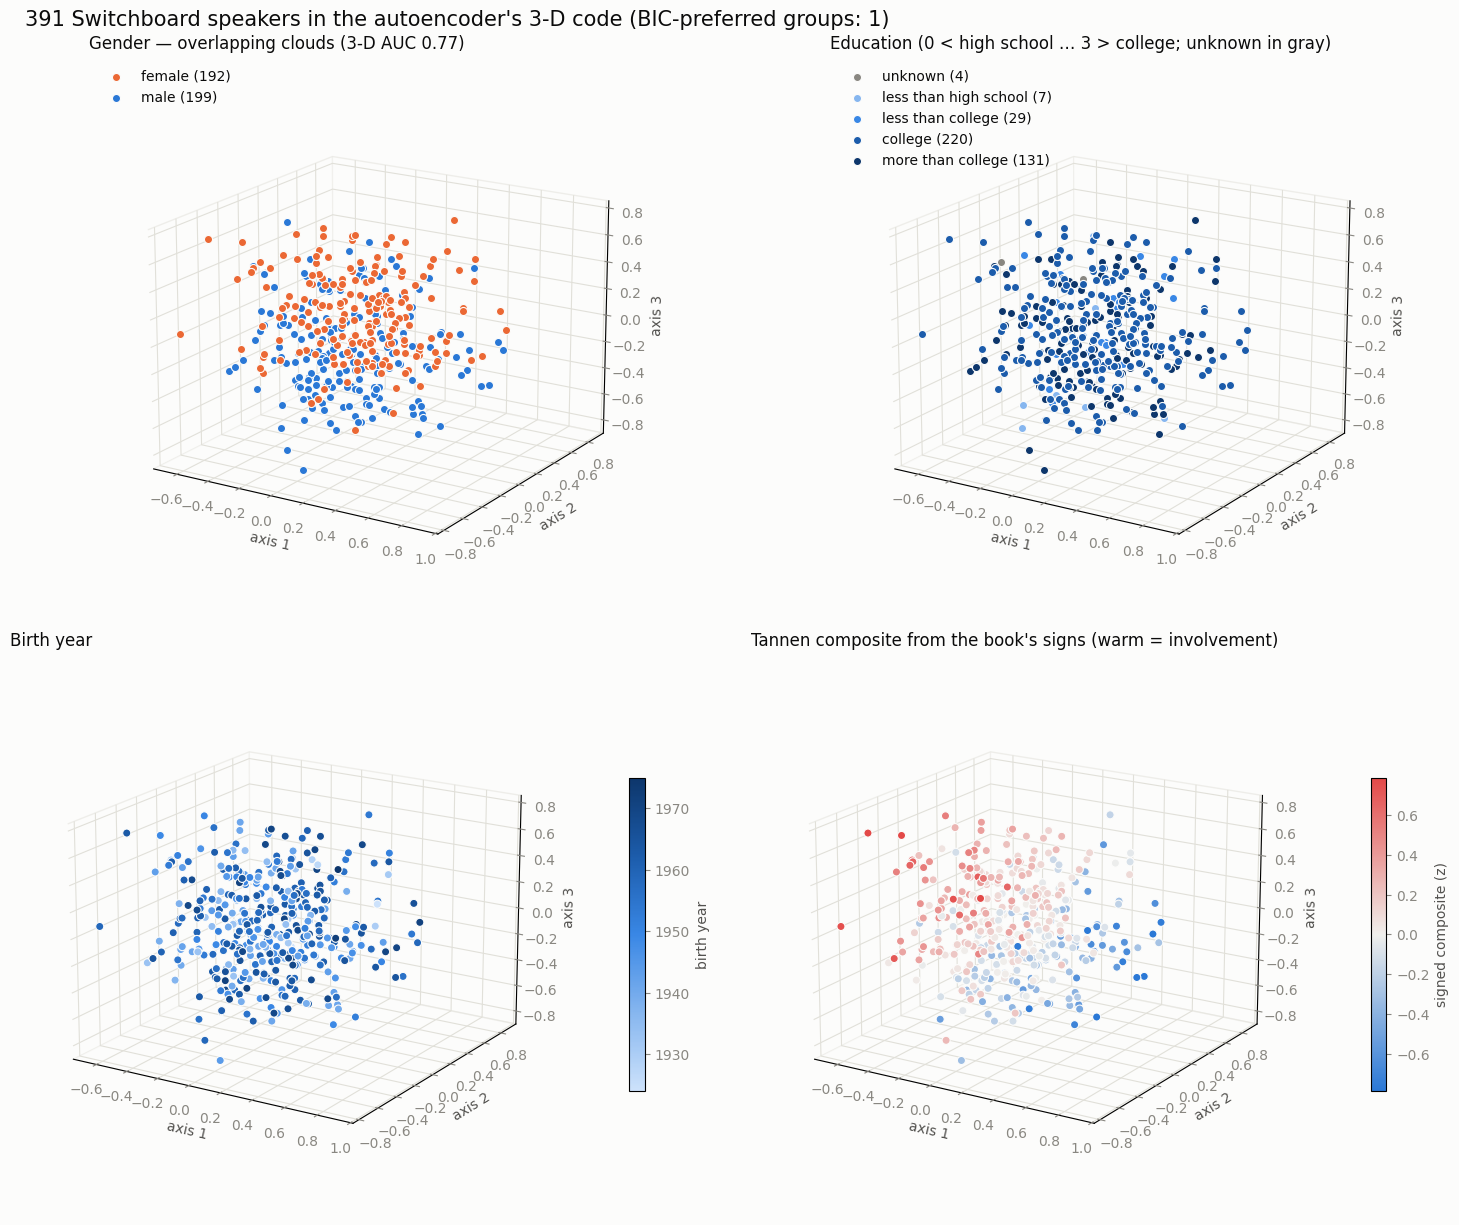

In [17]:
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"                      # categorical slots 1–2 (validated all-pairs)
EDU_RAMP = {0: "#86b6ef", 1: "#3987e5", 2: "#1c5cab", 3: "#0d366b"}   # ordinal blue 250/400/550/700 (validated --ordinal)
EDU_NAMES = {0: "less than high school", 1: "less than college", 2: "college", 3: "more than college"}
from matplotlib.colors import LinearSegmentedColormap
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", [BLUE, "#f0efec", "#e34948"])
plt.rcParams.update({"font.family": "sans-serif", "text.color": INK, "axes.labelcolor": INK2,
                     "xtick.color": MUTED, "ytick.color": MUTED, "figure.facecolor": SURF, "grid.color": GRID})
fig = plt.figure(figsize=(15, 12.5))
def panel(pos, title, grid=(2, 2)):
    ax = fig.add_subplot(*grid, pos, projection="3d", facecolor=SURF)
    ax.view_init(elev=18, azim=-58); ax.set_box_aspect(None, zoom=0.9)   # zoom out a touch so axis labels stay inside the panel
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_facecolor(SURF); a.pane.set_edgecolor(GRID)
    ax.set_xlabel("axis 1"); ax.set_ylabel("axis 2"); ax.set_zlabel("axis 3")
    ax.set_title(title, color=INK, fontsize=12, loc="left")
    return ax
kw = dict(s=34, edgecolors=SURF, linewidths=0.8, depthshade=False)
ax = panel(1, f"Gender — overlapping clouds (3-D AUC {auc_code:.2f})")
for lab, col, m_ in (("female", ORANGE, fem), ("male", BLUE, ~fem)):
    ax.scatter(*Z[m_].T, c=col, label=f"{lab} ({m_.sum()})", **kw)
ax.legend(frameon=False, loc="upper left")
ax = panel(2, "Education (0 < high school … 3 > college; unknown in gray)")
ax.scatter(*Z[~edu_m].T, c=MUTED, label=f"unknown ({(~edu_m).sum()})", **kw)
for lvl, col in EDU_RAMP.items():
    m_ = (DEMO["education"] == lvl).to_numpy()
    ax.scatter(*Z[m_].T, c=col, label=f"{EDU_NAMES[lvl]} ({m_.sum()})", **kw)
ax.legend(frameon=False, loc="upper left")
ax = panel(3, "Birth year")
sc = ax.scatter(*Z.T, c=DEMO["birth_year"], cmap=SEQ, **kw); fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.08, label="birth year")
ax = panel(4, "Tannen composite from the book's signs (warm = involvement)")
lim = np.abs(composite).quantile(0.98)
sc = ax.scatter(*Z.T, c=composite.clip(-lim, lim), cmap=DIV, vmin=-lim, vmax=lim, **kw)
fig.colorbar(sc, ax=ax, shrink=0.55, pad=0.08, label="signed composite (z)")
fig.suptitle(f"{len(Z)} Switchboard speakers in the autoencoder's 3-D code (BIC-preferred groups: {k_code})", x=0.02, ha="left", fontsize=15, color=INK)
plt.tight_layout(); plt.show()

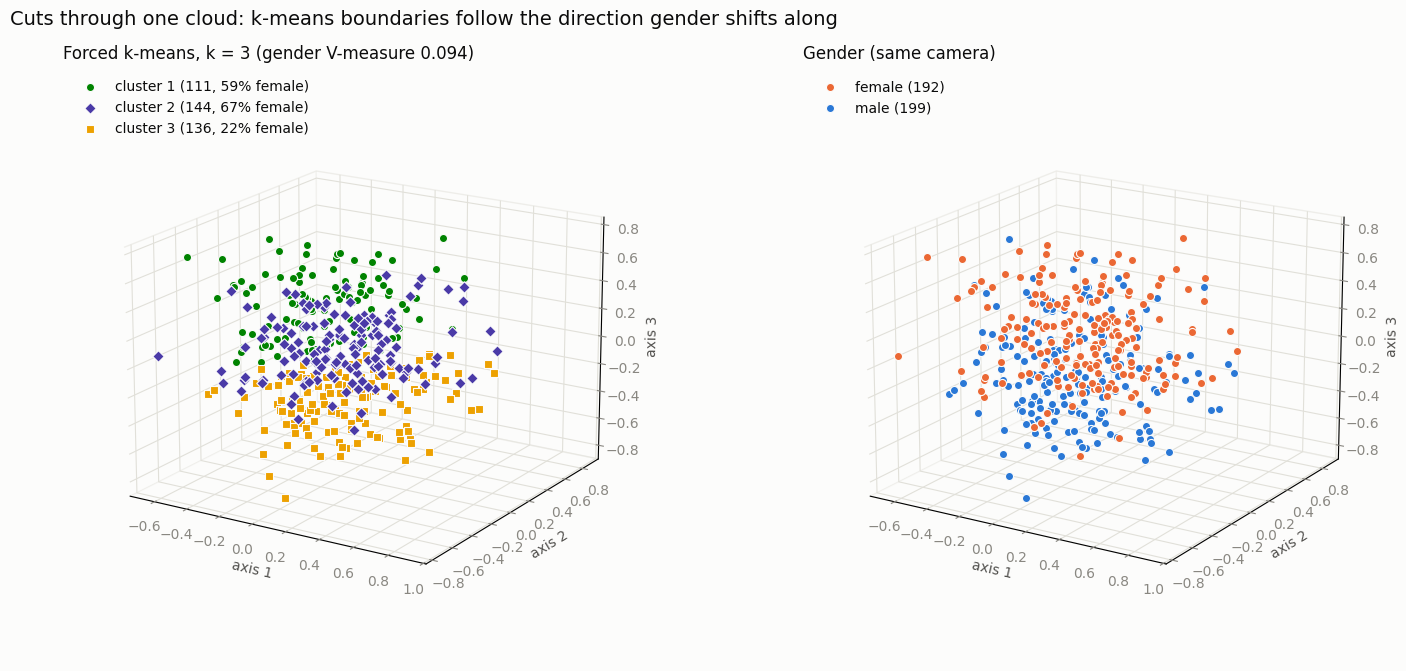

In [18]:
# Forced k-means cuts (S9b) beside gender, same camera: arbitrary slices of one cloud, and how they lean with gender.
CLUSTER_COLORS, CLUSTER_MARKERS = ["#008300", "#4a3aa7", "#eda100"], ["o", "D", "s"]   # slots 6/7/4, validated all-pairs; shape = 2nd channel
k3 = PART[("3-D code", 3)]
fig = plt.figure(figsize=(15, 6.8))
ax = panel(1, f"Forced k-means, k = 3 (gender V-measure {v_measure_score(yF, k3):.3f})", grid=(1, 2))
for j in range(3):
    m_ = k3 == j
    ax.scatter(*Z[m_].T, c=CLUSTER_COLORS[j], marker=CLUSTER_MARKERS[j], label=f"cluster {j + 1} ({m_.sum()}, {yF[m_].mean():.0%} female)", **kw)
ax.legend(frameon=False, loc="upper left")
ax = panel(2, "Gender (same camera)", grid=(1, 2))
for lab, col, m_ in (("female", ORANGE, fem), ("male", BLUE, ~fem)):
    ax.scatter(*Z[m_].T, c=col, label=f"{lab} ({m_.sum()})", **kw)
ax.legend(frameon=False, loc="upper left")
fig.suptitle("Cuts through one cloud: k-means boundaries follow the direction gender shifts along", x=0.02, ha="left", fontsize=14, color=INK)
plt.tight_layout(); plt.show()

In [19]:
# The interactive twin: plotly.js from a CDN, colour menu, hover per speaker, light and dark themes, table view.
pts = pd.DataFrame(Z, columns=["x", "y", "z"], index=C.index).join(DEMO[["sex", "education", "birth_year", "dialect"]])
pts["calls"] = C["n_sides"]; pts["composite"] = composite.round(3)
payload = {"caller": [int(c) for c in pts.index], **{k: pts[k].round(4).tolist() for k in ("x", "y", "z")},
           "sex": pts["sex"].str.lower().tolist(), "education": pts["education"].astype(int).tolist(),
           "birth_year": pts["birth_year"].astype(int).tolist(), "dialect": pts["dialect"].str.title().tolist(),
           "calls": pts["calls"].astype(int).tolist(), "composite": pts["composite"].tolist(),
           "k2": PART[("3-D code", 2)].tolist(), "k3": PART[("3-D code", 3)].tolist()}
SUBTITLE = (f"{len(pts)} speakers · {len(FEATS)} gold + in-house features · 3-unit autoencoder "
                 f"(medoid of {AE_SEEDS} restarts) · gender AUC {auc_code:.2f} · "
                 f"{'one cloud' if k_code == 1 else f'{k_code} BIC-preferred groups'} (Gaussian-mixture BIC, k = {k_code})")
out_html = write_map_html(DERIVED / "nb08_map_3d.html", payload, title="Switchboard speaker map", subtitle=SUBTITLE)
print(f"wrote {out_html} ({out_html.stat().st_size / 1024:.0f} KB)")

wrote /Users/dainbrownlow/switchboard/utterances_v2/derived/nb08_map_3d.html (102 KB)


## S11 — Sensitivity: two other ways to roll up

The primary map keeps all 391 callers and pulls one-call speakers toward the average (Kelley). Two
alternatives, same 25 features, same autoencoder settings, medoid of 20 restarts each: **A** — only the
callers seen in ≥3 base calls, plain caller means, no shrinkage; **B** — every side value first
stripped of its feature's average partner-sex shift (S9's actor/partner table), then the primary
roll-up. If the headline numbers move, they depend on the roll-up rather than on the speakers.
Last, a density check: shrinkage pulls callers with little data toward the average, so their points
crowd the centre of the map. The distance of each point from the centroid is correlated with the
number of calls behind it — a positive correlation means the dense core partly reflects thin data,
not similar speakers.

In [20]:
def medoid_code(Xv):
    cs = [encode(fit_ae(Xv, s_, H, ALPHA), Xv) for s_ in range(AE_SEEDS)]
    ds = [pdist(z) for z in cs]
    Mv = np.array([[spearmanr(ds[i], ds[j])[0] if i != j else np.nan for j in range(AE_SEEDS)] for i in range(AE_SEEDS)])
    return cs[int(np.nanargmax(np.nanmean(Mv, 1)))]

def headline(Zv, Xv, D):
    """The six headline numbers for one variant of the roll-up."""
    y, e = D["female"].to_numpy(), D["education"].isin([0, 1, 2, 3]).to_numpy()
    return [gmm_best_k(Zv, "full")[0], gmm_best_k(Xv, "tied")[0],
            np.mean([stat_gender(Zv, y, s_) for s_ in range(CV_SEEDS)]),
            np.mean([stat_gender(Xv, y, s_) for s_ in range(CV_SEEDS)]),
            np.mean([stat_r2(Zv[e], D["education"].to_numpy(float)[e], s_) for s_ in range(CV_SEEDS)]),
            np.mean([stat_r2(Xv, D["birth_year"].to_numpy(float), s_) for s_ in range(CV_SEEDS)])]

keep = C.index[C["n_sides"] >= 3]                                   # variant A
C3 = side_val[side_val["caller"].isin(keep)].groupby("caller")[FEATS].mean()
X3 = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(C3.fillna(C3.mean()))
Z3 = medoid_code(X3)

adj, icc_adj = side_val.copy(), {}                                  # variant B
for f in FEATS:
    v = side_val[f].to_numpy(); ok = ~np.isnan(v)
    b = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), S_female[ok], S_pfemale[ok]]), v[ok], rcond=None)[0]
    adj[f] = v - b[2] * S_pfemale
    d = adj[["caller", f]].dropna(); d = d[d["caller"].map(d["caller"].value_counts()) >= 2]
    icc_adj[f] = icc1(d[f].to_numpy(), d["caller"].to_numpy())
CB, _ = kelley_table(adj, FEATS, pd.Series(icc_adj))
XB = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(CB.loc[C.index, FEATS])
ZB = medoid_code(XB)

primary = [k_code, k_full, auc_code, auc_full,
           DEMO_TESTS.query("demographic == 'education 0–3 (R²)' and space == '3-D code'")["statistic"].item(),
           DEMO_TESTS.query("demographic == 'birth year (R²)' and space == 'full 25-D'")["statistic"].item()]
SENS = pd.DataFrame({"primary (391, Kelley)": primary,
                     f"A: ≥3 calls ({len(C3)}, plain means)": headline(Z3, X3, DEMO.loc[C3.index]),
                     "B: partner-sex adjusted (391)": headline(ZB, XB, DEMO)},
                    index=["best k, 3-D code", "best k, full space", "gender AUC, 3-D code", "gender AUC, full space",
                           "education R², 3-D code", "birth-year R², full space"])
print(SENS.round(3).to_string()); print(f"  {elapsed()}")
# Density check: empirical-Bayes shrinkage pulls callers with little data toward the centre, which can make
# the core of a map look denser than the speakers are. Distance from the centroid vs number of calls:
_rad = lambda z: np.linalg.norm(z - z.mean(0), axis=1)
RADIUS = {"3-D code (primary)": spearmanr(_rad(Z), C["n_sides"])[0], "t-SNE (primary)": spearmanr(_rad(tsne[0]), C["n_sides"])[0],
          "3-D code, variant A (no shrinkage)": spearmanr(_rad(Z3), C.loc[C3.index, "n_sides"])[0]}
_r1, _r3 = _rad(Z)[C["n_sides"].to_numpy() == 1], _rad(Z)[C["n_sides"].to_numpy() >= 3]
print("radius vs number of calls (Spearman): " + "; ".join(f"{k} {v:+.2f}" for k, v in RADIUS.items())
      + f" · median radius, 1-call {np.median(_r1):.3f} (n = {len(_r1)}) vs ≥3-call {np.median(_r3):.3f} (n = {len(_r3)})")

                           primary (391, Kelley)  A: ≥3 calls (220, plain means)  B: partner-sex adjusted (391)
best k, 3-D code                           1.000                           1.000                          1.000
best k, full space                         1.000                           1.000                          1.000
gender AUC, 3-D code                       0.771                           0.780                          0.762
gender AUC, full space                     0.806                           0.850                          0.799
education R², 3-D code                     0.008                           0.009                          0.006
birth-year R², full space                  0.111                           0.101                          0.111
  [540 s]
radius vs number of calls (Spearman): 3-D code (primary) +0.31; t-SNE (primary) +0.53; 3-D code, variant A (no shrinkage) -0.10 · median radius, 1-call 0.451 (n = 131) vs ≥3-call 0.548 (n = 220)


## S12 — Verdicts, each with the checks behind it; exports

In [21]:
def row(claim, value, checks):
    return {"claim": claim, "value": value, "checks": checks}
_gv = VM[VM["labels"] == "gender"]
V = pd.DataFrame([
    row("Gold extraction", f"{int(gold['n_units'].sum()):,} units, {int(gold['n_words'].sum()):,} words",
        f"unit tests; words r {CHECK_S2['words r (all sides)']:.3f} vs ms98 (swapped: {CHECK_S2['words r (swapped sides, mapped channel)']:.3f} mapped vs "
        f"{CHECK_S2['words r (swapped sides, OTHER channel)']:+.2f} other); questions r {CHECK_S2['questions r']:.2f}; "
        f"filled pauses r {CHECK_S2['filled pauses r ({F} vs um/uh)']:.2f}; laughter r {CHECK_S2['laughter r (two transcriptions)']:.2f}"),
    row("Topic model validity", f"topic recovery {CHECK_S3['topic_recovery']:.2f} vs majority {CHECK_S3['majority']:.3f}",
        f"K = 25 / 100: {TOPIC[25]['acc']:.2f} / {TOPIC[100]['acc']:.2f}"),
    row("Topic cohesion at turn level", f"mean {CHECK_S3['cohesion_obs']:+.4f}",
        f"shuffle z {CHECK_S3['shuffle_z']:.1f}; two code paths agree to 1e-9"),
    row("Topic cohesion as a speaker trait", f"ICC {ICC.loc['topic_cohesion', 'ICC']:+.3f} (CI {ICC.loc['topic_cohesion', 'lo']:+.3f}–{ICC.loc['topic_cohesion', 'hi']:+.3f})",
        f"persistence ICC {ICC.loc['topic_persistence', 'ICC']:+.3f}; raw uptake ICC by speaker {UPTAKE_ICC['local'][0]:+.2f} vs by "
        f"conversation {UPTAKE_ICC['local'][1]:+.2f}; side r across K "
        f"{_side[25]['cohesion'].corr(_side[50]['cohesion']):.2f} / {_side[50]['cohesion'].corr(_side[100]['cohesion']):.2f}"),
    row("Roll-up gate", f"{len(FEATS)} of {len(MAP)}", f"gate: ICC CI > 0; failed: {', '.join(failed)}"),
    row("Autoencoder stability", f"held-out R² {best['held-out R²']:.2f} (column-shuffled data {R2_INDEP:.2f})",
        f"{AE_SEEDS} restarts: distance ρ median {STAB['dist_rho_median']:.2f}; 10-NN overlap {STAB['knn_overlap_median']:.2f} (chance {STAB['knn_chance']:.3f}); trustworthiness {STAB['trust']:.2f}"),
    row("Clusters", f"BIC k = {k_code} (code), {k_full} (full)",
        f"distance dip p {DIP['3-D code'][1]:.2f} / {DIP['full 25-D'][1]:.2f}; null k = 1 in {(NULL.k_code == 1).mean():.0%}; t-SNE k {tsne_k}; power: ≥50% detection from Δ ≈ "
        f"{POWER.loc[POWER['detected in 3-D code'] >= 0.5, 'Mahalanobis Δ'].min()}; variants A/B k = {int(SENS.iloc[0, 1])}/{int(SENS.iloc[0, 2])} (code), {int(SENS.iloc[1, 1])}/{int(SENS.iloc[1, 2])} (full)"),
    row("Gender in the map", f"AUC {auc_code:.2f} (code) / {auc_full:.2f} (full)",
        f"perm p {DEMO_TESTS.iloc[0]['p (BH-FDR)']:.4f}; restarts {auc_seeds.min():.2f}–{auc_seeds.max():.2f}; variant A {SENS.iloc[2, 1]:.2f}, B {SENS.iloc[2, 2]:.2f}; Δ ≈ {np.sqrt(2) * norm.ppf(auc_code):.1f}"),
    row("Education in the map", f"R² {DEMO_TESTS.iloc[2]['statistic']:.3f} (code) / {DEMO_TESTS.iloc[3]['statistic']:.3f} (full)",
        f"FDR p {DEMO_TESTS.iloc[2]['p (BH-FDR)']:.3f} / {DEMO_TESTS.iloc[3]['p (BH-FDR)']:.3f}; restarts {edu_seeds.min():.3f}–{edu_seeds.max():.3f}"),
    row("Birth year in the map", f"R² {DEMO_TESTS.iloc[5]['statistic']:.3f} (full) vs {DEMO_TESTS.iloc[4]['statistic']:.3f} (code)",
        f"FDR p {DEMO_TESTS.iloc[5]['p (BH-FDR)']:.3f} / {DEMO_TESTS.iloc[4]['p (BH-FDR)']:.3f}; restarts {by_seeds.min():.3f}–{by_seeds.max():.3f}"),
    row("Dialect region in the map", f"macro AUC {DEMO_TESTS.iloc[6]['statistic']:.3f} (code) / {DEMO_TESTS.iloc[7]['statistic']:.3f} (full)",
        f"FDR p {DEMO_TESTS.iloc[6]['p (BH-FDR)']:.3f} / {DEMO_TESTS.iloc[7]['p (BH-FDR)']:.3f}"),
    row("Forced clusters vs demographics (V-measure)",
        f"gender V {_gv.V.min():.2f}–{_gv.V.max():.2f} over k = 2–8 (shuffled ≈ {_gv['V shuffled'].mean():.3f})",
        f"best possible gender split V {CEILING['3-D code']:.2f} / {CEILING['full 25-D']:.2f}; 3-D k = 2 cut across restarts "
        f"{min(VM_RESTARTS[2]):.2f}–{max(VM_RESTARTS[2]):.2f}; nothing beyond gender (conditional MI min q "
        f"{CMI['q (BH-FDR)'].min():.2f}); region significant at any k: {bool((VM.loc[VM['labels'] == 'region', 'q (BH-FDR)'] < .05).any())}"),
    row("Map density vs data amount", f"radius–calls ρ {RADIUS['3-D code (primary)']:+.2f} (t-SNE {RADIUS['t-SNE (primary)']:+.2f})",
        f"variant A, no shrinkage: {RADIUS['3-D code, variant A (no shrinkage)']:+.2f}; median radius 1-call {np.median(_r1):.2f} vs ≥3-call {np.median(_r3):.2f}"),
    row("Book-signed involvement composite in the map", f"composite read-out R² {read_primary:.2f}",
        f"{AE_SEEDS} restarts {read_all.min():.2f}–{read_all.max():.2f}"),
])
with pd.option_context("display.max_colwidth", 200, "display.width", 250):
    print(V.to_string(index=False))

EXPORT = C[FEATS].join(pd.DataFrame(Z, columns=["ae1", "ae2", "ae3"], index=C.index)) \
                 .join(pd.DataFrame(tsne[0], columns=["tsne1", "tsne2", "tsne3"], index=C.index)) \
                 .assign(n_sides=C["n_sides"], tannen_composite=composite).join(DEMO)
EXPORT.index.name = "caller"
EXPORT.to_csv(DERIVED / "nb08_speaker_map.csv")
gold.to_csv(DERIVED / "gold_side.csv", index=False)
ICC.to_csv(DERIVED / "nb08_feature_icc.csv")
side_val[FEATS].assign(conv=S["conv"], side=S["side"], caller=S["caller"], female=S_female,
                       partner_female=S_pfemale).to_csv(DERIVED / "nb08_side_values.csv", index=False)   # NB09's variants A/B
print(f"\nexports → {DERIVED}: nb08_speaker_map.csv ({EXPORT.shape[0]}×{EXPORT.shape[1]}), gold_side.csv "
      f"({len(gold)} sides), nb08_feature_icc.csv, nb08_side_values.csv, nb08_map_3d.html · total runtime {elapsed()}")

                                       claim                                              value                                                                                                                                                                   checks
                             Gold extraction                     183,151 units, 1,311,602 words                                        unit tests; words r 0.998 vs ms98 (swapped: 0.998 mapped vs -0.09 other); questions r 0.92; filled pauses r 0.90; laughter r 0.80
                        Topic model validity              topic recovery 0.69 vs majority 0.032                                                                                                                                                K = 25 / 100: 0.69 / 0.76
                Topic cohesion at turn level                                       mean +0.0288                                                                                                              

## S13 — What the map shows (plain summary of the 2026-09-29 run)

**Human annotation yields 15 Tannen features no automatic extractor here reached.** From SwDA's dialog
acts and transcription markup: questions, echo/backchannel questions, continuers, appreciations,
collaborative completions, repeats of the other's words, expanded answers, quotations, opinions,
hedges, filled pauses, restarts, unit length, word share and laughter. The counts agree with an
independent transcription of the same audio (words r .998 — and −.09 against the wrong channel of the
83 swapped conversations — questions .92, filled pauses .90, laughter .80) and with a parser-free
recount (1,972 of 1,972 sides). Transcriber overlap marks exist in only 53% of conversations, so
overlap stays with the aligned word times (the in-house cooperative/obstructive split).

**The topic model works; topic cohesion is not a speaker trait.** LDA recovers each conversation's
assigned topic 69% of the time (majority class 3.2%). Turns do pick up the partner's last turn beyond
the conversation's shared topic (shuffle z 20.7). But how much a speaker does this does not repeat
across their calls (ICC −.002); raw topical uptake belongs to the conversation (ICC by conversation
.42 vs by speaker .04). Tannen's dim 7 is measurable here at the dyad level, not the speaker level.

**25 of 29 candidates describe speakers** (ICC CI above 0), from restarts and syllable rate (.62) down
to expanded answers (.05); machine-gun questions and both topic columns do not.

**No clusters.** One Gaussian component fits the 3-D code and the full 25-feature space; the
distance-distribution dip test finds nothing (p 1.00 / 1.00, while a known two-group case gives
p < .001); 30 structureless twins, t-SNE (and t-SNE of the twins), and both alternative roll-ups agree.
The limit of that statement: this pipeline sees two equal groups only once they sit about 5 Mahalanobis
units apart (90–95% detection at 5, 20–25% at 4, 0% at ≤ 3). So: no well-separated speaker types;
closer groupings cannot be ruled out by clustering at n = 391.

**Forced clusters line up with gender, and only with gender.** Cutting the cloud anyway (k-means,
k = 2–8) and scoring the cuts against demographic labels by V-measure: gender V .05–.10 at every k in
both spaces (label shuffles ≈ .004; chance-corrected AMI the same), which reaches up to 80% (map) and 65%
(full space) of what a split following gender perfectly would score (.12 / .15) — men and women overlap
too much for any cut to do better. In the 3-D map this holds from k = 3 up (k = 3: V .06–.10 across all 20
restarts; the medoid map's three cuts are 59%, 67% and 22% female); a single k = 2 cut follows gender in
some restarts and not others (V .00–.14, median .01). Education and age line up only faintly (V ≤ .04,
AMI ≤ .02, significant at some k), region never, and none of education, age, region or their
combinations adds anything once gender is known (conditional mutual information, smallest FDR q .31).

**Gender moves the cloud; it does not split it.** Position predicts gender at AUC .77 (3-D code) and
.81 (all 25 features), permutation p = .001 (FDR .003), .75–.77 across all 20 restarts, .71–.75 in
t-SNE, .76–.85 in both alternative roll-ups — a separation of Δ ≈ 1.0–1.2, a fifth of what it would take
to form visible groups. Women laugh more (d +.82), use more personal pronouns (+.52), appreciations
(+.42), cooperative overlap (+.36) and continuers (+.24); they use shorter units (−.69), fewer restarts
(−.58) and filled pauses (−.36), fewer opinion statements (−.48), faster floor transfers (−.51) and a
slower syllable rate (−.52). Most of this is the speaker's own sex; floor-transfer speed shifts as much
with the partner's sex (−.36 own, −.37 partner; −.27 within the same caller), and women's calls were
more often with women (63% vs 51%). Removing the partner-sex shift leaves gender AUC at .76 / .80. On the
book-signed involvement composite women score higher (d +.36, p = .0004).

**Age is in the features but not in the map; education barely registers; region does not.** Birth year
is predictable from the 25 features (R² .11, p = .001) but not from the 3-D code (R² −.01): older
speakers take a larger share of the words and longer units, younger ones laugh and hedge more — variation
the three axes do not keep. Education (0 less than high school … 3 more than college) reaches FDR
p .04–.05 but explains under 1% of variance (R² .008 / .005; NB07's coding, which dropped code 0, gives
.02). Dialect region is at chance (macro AUC .46 / .50).

**What the three axes are** (correlations with the inputs, medoid restart). **Axis 1**: fast, voluble,
quoting, self-repeating talk (syllable rate −.70, own-line repetition −.63, word share −.63, quotation
−.55, unit length −.50) against hesitant, questioning, laughing talk (filled pauses +.44, laughter +.41,
questions +.39). **Axis 2**: engaged-but-disfluent listening (cooperative overlap −.50, restarts −.47,
continuers −.46, within-turn pauses −.43) against slow floor transfers (+.50) with more obstructive
overlaps (+.32). **Axis 3**: rapport (cooperative overlap +.45, appreciations +.43, personal pronouns
+.38, laughter +.36, latching +.31) against long, disfluent units (restarts −.66, unit length −.58,
filled pauses −.57) — the axis gender lies along (r .46). The book-signed composite is 76% linearly
recoverable from the three coordinates (72–81% across restarts), mostly along axis 3.

**Limits.** One corpus of strangers on assigned topics over the telephone; 391 speakers, median 3
calls. Shrinkage places one-call speakers nearer the centre (radius–calls ρ +.31, t-SNE +.53; −.10
without shrinkage), so the dense core partly reflects thin data. The signs are the book's, applied to a
corpus it was not written about; the decision rules were fixed after prototyping on the same data.